# Capítulo 9 — Inferência bayesiana com erros gaussianos
**Igor Stellet · Estatística Bayesiana · 2026.2**

Voltamos à pergunta bayesiana: **o que os dados dizem sobre os parâmetros e sobre os modelos, dadas as hipóteses do experimento?** A distribuição atribuída aos erros constrói a likelihood; a prior e a marginalização completam a inferência.

Seguiremos os **slides 4–34 da Parte 3**, o **capítulo 9 do Gregory, pp. 212–240**, e as contas do **Apêndice C, pp. 434–444**. A ideia do notebook é:

1. Revisão curta: dos erros à likelihood.
2. Estimar uma média nos três regimes de informação sobre o ruído.
3. Marginalizar o ruído, obter a Student e inferir a própria escala $\sigma$.
4. Reproduzir o exemplo de rádio: erro instrumental e dispersão adicional.
5. Comparar as duas amostras de toxina: quatro modelos, evidências, diferença de médias e razão de desvios padrão.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special, integrate, optimize
from numpy.polynomial.legendre import leggauss
from IPython.display import display, Markdown

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 220,
                     'font.size': 11, 'axes.titlesize': 12,
                     'legend.fontsize': 9, 'grid.alpha': .2,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})
AZUL, VERDE, OURO, ROXO, VERMELHO = '#2878B5', '#27856D', '#B58618', '#8055A3', '#BD5254'
SALVAR_ARQUIVOS = False
BASE = Path.cwd()  # Pasta de execução do kernel.
PASTA_FIGURAS = BASE / 'figuras' / 'capitulo_9'
PASTA_TABELAS = BASE / 'tabelas' / 'capitulo_9'
checks, figuras = [], []

def verificar(nome, condicao):
    if not np.all(condicao):
        raise AssertionError(nome)
    checks.append(nome)

def figura(fig, nome):
    figuras.append(nome)
    if SALVAR_ARQUIVOS:
        PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
        for ext in ('png', 'pdf'):
            fig.savefig(PASTA_FIGURAS / f'{nome}.{ext}', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def tabela(df, nome=None, casas=5):
    display(df.round(casas))
    if SALVAR_ARQUIVOS and nome:
        PASTA_TABELAS.mkdir(parents=True, exist_ok=True)
        df.to_csv(PASTA_TABELAS / f'{nome}.csv', index=False)

def resumo_dados(x):
    x = np.asarray(x, dtype=float)
    return len(x), x.mean(), np.sum((x-x.mean())**2)

def normalizar(x, y):
    area = integrate.trapezoid(y, x)
    if not np.isfinite(area) or area <= 0:
        raise ValueError('A densidade precisa ter integral positiva e finita.')
    return y / area

def resumo_grade(x, p):
    p = normalizar(x, p)
    F = integrate.cumulative_trapezoid(p, x, initial=0)
    F /= F[-1]
    return {'Moda': x[np.argmax(p)], 'Média': integrate.trapezoid(x*p, x),
            'Mediana': np.interp(.5, F, x),
            'IC central 95% inf.': np.interp(.025, F, x),
            'IC central 95% sup.': np.interp(.975, F, x)}

print('Exportação opcional:', SALVAR_ARQUIVOS)

Exportação opcional: False


## 1. Revisão curta — dos erros à likelihood

Escrevemos uma medida como $d_i=m_i(\theta)+e_i$. Se atribuímos ao erro uma densidade $g_i(e_i)$, a transformação $e_i=d_i-m_i(\theta)$ tem jacobiano unitário, para $\theta$ fixo. Logo,

$$p(d_i\mid\theta,I)=g_i\!\left[d_i-m_i(\theta)\right].$$

Para **erros independentes, condicionados no modelo e nos parâmetros**, multiplicamos as densidades. Com $e_i\sim\mathcal N(0,\sigma_i^2)$,

$$L(\theta)=p(D\mid\theta,I)=\prod_{i=1}^N\frac{1}{\sqrt{2\pi}\sigma_i}
\exp\!\left[-\frac{(d_i-m_i(\theta))^2}{2\sigma_i^2}\right].$$

Os dados observados ficam fixos e variamos os parâmetros. Bayes fornece

$$p(\theta\mid D,I)=\frac{p(\theta\mid I)L(\theta)}{Z},\qquad
Z=p(D\mid I)=\int p(\theta\mid I)L(\theta)\,d\theta.$$

A independência justifica o produto; a hipótese gaussiana justifica cada fator. No capítulo, $m_i(\theta)=\mu$ é uma constante. As constantes de normalização podem cancelar ao estimar um parâmetro dentro de um modelo; **para comparar modelos, preservaremos todos os fatores**.

Se a própria previsão verdadeira $z_i$ tem uma distribuição, retomamos a marginalização da Parte 1: $p(d_i\mid\theta)=\int p(z_i\mid\theta)g_i(d_i-z_i)dz_i$, uma convolução para erro aditivo independente. Uma previsão determinística concentra $p(z_i\mid\theta)$ em $m_i(\theta)$ e recupera a primeira expressão.

## 2. Uma média com $\sigma$ conhecido e igual

Assumimos $d_i=\mu+e_i$, com $e_i\overset{\mathrm{ind}}\sim\mathcal N(0,\sigma_0^2)$ e $\sigma_0$ conhecido. Definimos

$$\bar d=\frac1N\sum_i d_i,\qquad q=\sum_i(d_i-\bar d)^2,\qquad
r_{\rm RMS}=\sqrt{q/N},\qquad S^2=\frac{q}{N-1}.$$

$q$ é a soma dos quadrados dos resíduos do melhor ajuste constante; $r_{\rm RMS}$ mede sua dispersão. $S^2$ é a variância amostral. Já a largura da posterior da média mede a incerteza sobre $\mu$.

### 2.1 Separar a parte que depende da média

Somamos e subtraímos $\bar d$ dentro de cada resíduo:

$$\begin{aligned}
Q(\mu)&=\sum_i\big[(d_i-\bar d)+(\bar d-\mu)\big]^2\\
&=\sum_i(d_i-\bar d)^2
+2(\bar d-\mu)\underbrace{\sum_i(d_i-\bar d)}_{\sum_i d_i-N\bar d=0}
+N(\bar d-\mu)^2\\
&=q+N(\mu-\bar d)^2.
\end{aligned}$$

Portanto,

$$L(\mu)=\underbrace{(2\pi)^{-N/2}\sigma_0^{-N}
 e^{-q/(2\sigma_0^2)}}_{A(D,\sigma_0)}
 e^{-N(\mu-\bar d)^2/(2\sigma_0^2)}.$$

### 2.2 Prior uniforme: expressão exata e aproximação ampla

Escolhemos $p(\mu\mid I)=1/R_\mu$ em $[L,H]$, com $R_\mu=H-L$. A normalização é

$$Z=\frac{A}{R_\mu}\int_L^H
 e^{-(\mu-\bar d)^2/(2u^2)}\,d\mu
=\frac{A}{R_\mu}\sqrt{2\pi}u\,A_\mu,$$

onde $u=\sigma_0/\sqrt N$ e

$$A_\mu=\Phi\!\left(\frac{H-\bar d}{u}\right)
-\Phi\!\left(\frac{L-\bar d}{u}\right),\qquad
\Phi(z)=\int_{-\infty}^z\frac{e^{-t^2/2}}{\sqrt{2\pi}}\,dt.$$

Dividindo o numerador por $Z$,

$$p(\mu\mid D,I)=\frac{e^{-(\mu-\bar d)^2/(2u^2)}}{\sqrt{2\pi}u A_\mu}
\,\mathbf1_{[L,H]}(\mu).$$

Temos uma **normal truncada**. Se ambas as bordas estão a muitas larguras $u$ da região favorecida pelos dados, $A_\mu\simeq1$ e

$$\boxed{\mu\mid D,I\simeq\mathcal N(\bar d,\sigma_0^2/N).}$$

É a distância das bordas à região posterior, medida em unidades de $u$, que controla essa aproximação. A variância posterior cai como $1/N$ e o desvio padrão como $1/\sqrt N$.

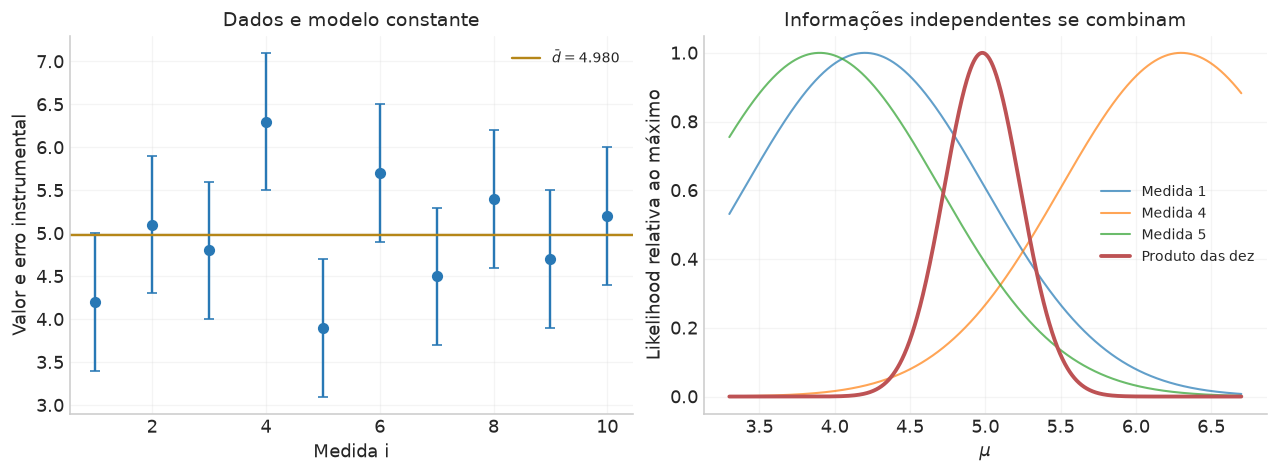

,Quantidade,Valor
0,N,10.00000
1,Média,4.98000
2,q,4.61600
3,RMS residual,0.67941
4,S,0.71616
5,Desvio posterior de μ,0.25298


In [2]:
# Exemplo didático fixo, em uma unidade arbitrária de medida.
d = np.array([4.2, 5.1, 4.8, 6.3, 3.9, 5.7, 4.5, 5.4, 4.7, 5.2])
N, dbar, q = resumo_dados(d)
r_rms, S = np.sqrt(q/N), np.sqrt(q/(N-1))
sigma0 = .8
u_mu = sigma0/np.sqrt(N)
mu_grid = np.linspace(3.3, 6.7, 1601)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
ax[0].errorbar(np.arange(1,N+1), d, yerr=sigma0, fmt='o', capsize=3, color=AZUL)
ax[0].axhline(dbar, color=OURO, label=fr'$\bar d={dbar:.3f}$')
ax[0].set(xlabel='Medida i', ylabel='Valor e erro instrumental', title='Dados e modelo constante')
ax[0].legend()
for i in [0, 3, 4]:
    Li = stats.norm.pdf(d[i], loc=mu_grid, scale=sigma0)
    ax[1].plot(mu_grid, Li/Li.max(), lw=1.3, alpha=.7, label=f'Medida {i+1}')
Llog = np.sum(stats.norm.logpdf(d[:,None], loc=mu_grid, scale=sigma0), axis=0)
ax[1].plot(mu_grid, np.exp(Llog-Llog.max()), color=VERMELHO, lw=2.4, label='Produto das dez')
ax[1].set(xlabel=r'$\mu$', ylabel='Likelihood relativa ao máximo', title='Informações independentes se combinam')
ax[1].legend()
figura(fig, '01_dados_e_likelihood')

verificar('Decomposição da soma de quadrados', np.allclose(
    ((d[:,None]-mu_grid)**2).sum(axis=0), q+N*(mu_grid-dbar)**2))
tabela(pd.DataFrame({'Quantidade':['N','Média','q','RMS residual','S','Desvio posterior de μ'],
                     'Valor':[N,dbar,q,r_rms,S,u_mu]}), 'resumo_exemplo')

Cada medida favorece uma faixa larga de valores de $\mu$. O produto concentra a informação na região comum. As curvas individuais foram divididas por seus próprios máximos apenas para visualizar suas formas; a conta da posterior usa a densidade completa.

Podemos enxergar o papel da prior de duas maneiras: restringir seu suporte ou informar uma localização preferida. Para uma prior gaussiana $\mu\sim\mathcal N(m_0,\tau_0^2)$,

$$-2\log p(\mu\mid D)=\frac{N}{\sigma_0^2}(\mu-\bar d)^2
+\frac{(\mu-m_0)^2}{\tau_0^2}+\text{constante}.$$

Reunindo os termos quadráticos e lineares em $\mu$,

$$u_p^{-2}=N/\sigma_0^2+\tau_0^{-2},\qquad
m_p=u_p^2\left(N\bar d/\sigma_0^2+m_0/\tau_0^2\right).$$

A posterior é $\mathcal N(m_p,u_p^2)$. A precisão da prior se soma à precisão dos dados. Uma prior muito larga recupera o resultado centrado em $\bar d$.

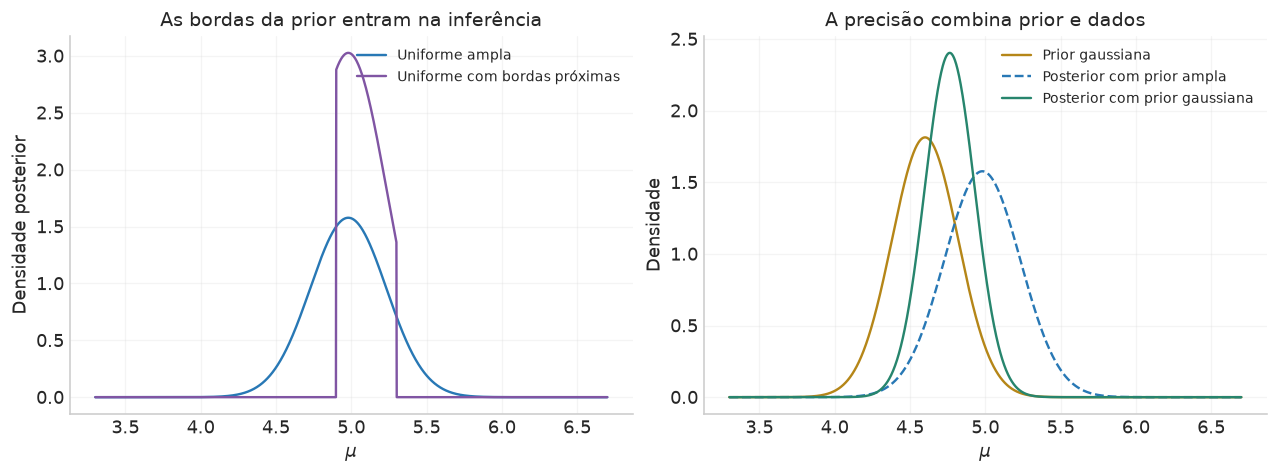

Prior ampla: μ = 4.980 ± 0.253; prior gaussiana: μ = 4.764 ± 0.166.


In [3]:
prior_bounds = [(3.3,6.7), (4.9,5.3)]
fig, ax = plt.subplots(1,2,figsize=(11,4),layout='constrained')
for (lo,hi), cor, rotulo in zip(prior_bounds, [AZUL,ROXO], ['Uniforme ampla','Uniforme com bordas próximas']):
    post = stats.truncnorm((lo-dbar)/u_mu,(hi-dbar)/u_mu,loc=dbar,scale=u_mu)
    ax[0].plot(mu_grid, post.pdf(mu_grid), color=cor, label=rotulo)
    verificar(f'Normal truncada normalizada [{lo},{hi}]',
              np.isclose(integrate.quad(post.pdf,lo,hi)[0],1,atol=1e-9))
ax[0].set(xlabel=r'$\mu$',ylabel='Densidade posterior',title='As bordas da prior entram na inferência')
ax[0].legend()
m0,tau0=4.6,.22
up=1/np.sqrt(N/sigma0**2+1/tau0**2)
mp=up**2*(N*dbar/sigma0**2+m0/tau0**2)
ax[1].plot(mu_grid,stats.norm.pdf(mu_grid,m0,tau0),color=OURO,label='Prior gaussiana')
ax[1].plot(mu_grid,stats.norm.pdf(mu_grid,dbar,u_mu),color=AZUL,ls='--',label='Posterior com prior ampla')
ax[1].plot(mu_grid,stats.norm.pdf(mu_grid,mp,up),color=VERDE,label='Posterior com prior gaussiana')
ax[1].set(xlabel=r'$\mu$',ylabel='Densidade',title='A precisão combina prior e dados')
ax[1].legend()
figura(fig,'02_papel_da_prior')
print(f'Prior ampla: μ = {dbar:.3f} ± {u_mu:.3f}; prior gaussiana: μ = {mp:.3f} ± {up:.3f}.')

Com prior ampla, o intervalo central de credibilidade de 95% tem os mesmos limites numéricos de $\bar d\pm1{,}96\sigma_0/\sqrt N$. Na leitura bayesiana, ele contém 95% da probabilidade posterior para $\mu$, condicionada nos dados e nas hipóteses. Na leitura frequentista, a probabilidade se refere à cobertura do procedimento em repetições. A coincidência dos limites neste modelo preserva as duas interpretações próprias.

## 3. $\sigma_i$ conhecidos e distintos: a média ponderada

Agora cada medida tem uma precisão conhecida diferente. Definimos

$$w_i=\frac1{\sigma_i^2},\qquad W=\sum_iw_i,\qquad
\bar d_w=\frac{\sum_iw_id_i}{W}.$$

A likelihood é

$$L(\mu)=(2\pi)^{-N/2}\left(\prod_i\sigma_i^{-1}\right)
 e^{-Q_w(\mu)/2},\qquad Q_w(\mu)=\sum_iw_i(d_i-\mu)^2.$$

Abrindo os quadrados em torno de $\bar d_w$,

$$\begin{aligned}
Q_w(\mu)&=\sum_iw_i(d_i-\bar d_w)^2
+2(\bar d_w-\mu)\underbrace{\sum_iw_i(d_i-\bar d_w)}_{0}
+W(\mu-\bar d_w)^2\\
&=q_w+W(\mu-\bar d_w)^2.
\end{aligned}$$

O cancelamento do termo cruzado segue de $\sum_iw_id_i=W\bar d_w$. Com prior uniforme ampla,

$$\boxed{\mu\mid D,I\simeq\mathcal N\!\left(\bar d_w,\frac1W\right).}$$

Para prior uniforme finita, usamos a mesma normal truncada da seção anterior, trocando $\bar d\to\bar d_w$ e $u\to1/\sqrt W$. A medida com menor $\sigma_i$ recebe maior peso. Se todos os $\sigma_i=\sigma_0$, então $\bar d_w=\bar d$ e $1/W=\sigma_0^2/N$.

Usaremos as dez medidas de tensão e seus erros do **problema 9.1 do Gregory, p. 241**, como exemplo concreto deste caso.

,Medida,V,σ_i,w_i/W
0,1,4.36,2.24,0.03689
1,2,4.00,1.94,0.04918
2,3,4.87,1.39,0.09581
3,4,5.64,2.55,0.02847
4,5,6.14,1.69,0.06481
5,6,5.92,1.38,0.09720
6,7,3.93,1.00,0.18511
7,8,6.58,1.60,0.07231
8,9,3.78,1.00,0.18511
9,10,5.84,1.00,0.18511


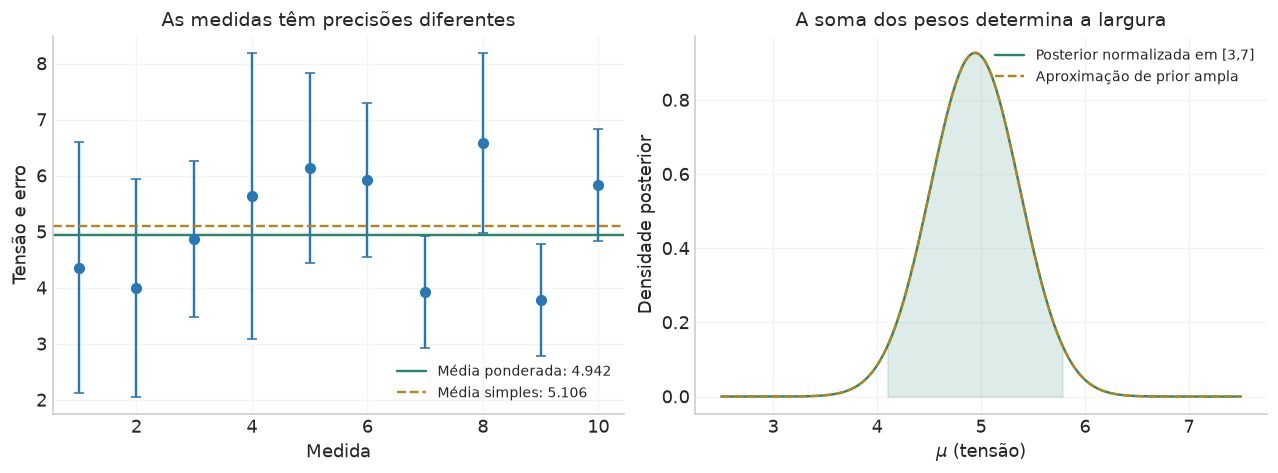

Centro da normal não truncada: 4.942118; escala: 0.430243.
Posterior finita: média = 4.942123; IC central 95% = [4.098879, 5.785374].


In [5]:
V = np.array([4.36,4.00,4.87,5.64,6.14,5.92,3.93,6.58,3.78,5.84])
erroV = np.array([2.24,1.94,1.39,2.55,1.69,1.38,1.,1.60,1.,1.])
w = 1/erroV**2
W = w.sum()
Vw = np.sum(w*V)/W
uw = 1/np.sqrt(W)
vg = np.linspace(2.5,7.5,1501)
lo,hi=3.,7.
pv = stats.truncnorm((lo-Vw)/uw,(hi-Vw)/uw,loc=Vw,scale=uw)
tabela(pd.DataFrame({'Medida':np.arange(1,len(V)+1),'V':V,'σ_i':erroV,'w_i/W':w/W}), 'pesos_tensao')
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].errorbar(np.arange(1,len(V)+1),V,yerr=erroV,fmt='o',capsize=3,color=AZUL)
ax[0].axhline(Vw,color=VERDE,label=fr'Média ponderada: {Vw:.3f}')
ax[0].axhline(V.mean(),color=OURO,ls='--',label=fr'Média simples: {V.mean():.3f}')
ax[0].set(xlabel='Medida',ylabel='Tensão e erro',title='As medidas têm precisões diferentes')
ax[0].legend()
ax[1].plot(vg,pv.pdf(vg),color=VERDE,label='Posterior normalizada em [3,7]')
ax[1].plot(vg,stats.norm.pdf(vg,Vw,uw),ls='--',color=OURO,label='Aproximação de prior ampla')
a,b=pv.ppf([.025,.975])
ax[1].fill_between(vg,0,pv.pdf(vg),where=(vg>=a)&(vg<=b),color=VERDE,alpha=.15)
ax[1].set(xlabel=r'$\mu$ (tensão)',ylabel='Densidade posterior',title='A soma dos pesos determina a largura')
ax[1].legend()
figura(fig,'03_media_ponderada')
print(f'Centro da normal não truncada: {Vw:.6f}; escala: {uw:.6f}.')
print(f'Posterior finita: média = {pv.mean():.6f}; IC central 95% = [{a:.6f}, {b:.6f}].')
qw=np.sum(w*(V-Vw)**2)
verificar('Decomposição ponderada',np.allclose(np.sum(w[:,None]*(V[:,None]-vg)**2,axis=0),qw+W*(vg-Vw)**2))

## 4. $\sigma$ desconhecido e comum: construir e marginalizar

Retomamos o conjunto didático $d$ da seção 2. Agora sua escala comum também é um parâmetro. A likelihood conjunta é

$$L(\mu,\sigma)=(2\pi)^{-N/2}\sigma^{-N}
\exp\!\left[-\frac{q+N(\mu-\bar d)^2}{2\sigma^2}\right].$$

A normalização $\sigma^{-N}$ carrega informação sobre a escala: valores muito grandes espalham a probabilidade por uma faixa muito larga de possíveis medidas.

### 4.1 Escolha da prior e mudança de $\sigma$ para $\sigma^2$

Seguimos a escolha do capítulo: prior uniforme em $\mu\in[L,H]$ e prior de escala em $a\leq\sigma\leq b$,

$$p(\mu,\sigma\mid I)=\frac1{R_\mu}\frac1{\sigma\log(b/a)},\qquad 0<a<b.$$

A prior de escala é uniforme em $\eta=\log\sigma$, pois $d\eta=d\sigma/\sigma$. Aqui usamos a prior de escala de Jeffreys e a prior de localização independentes adotadas pelo curso, $p(\mu,\sigma)\propto1/\sigma$. A aplicação da regra conjunta de Jeffreys ao par $(\mu,\sigma)$ produz outra escolha, $1/\sigma^2$; manteremos a primeira ao longo do notebook.

Se $v=\sigma^2$, então $\sigma=\sqrt v$ e $|d\sigma/dv|=1/(2\sqrt v)$. Assim,

$$p(v\mid I)=\frac1{\sqrt v\log(b/a)}\frac1{2\sqrt v}
=\frac1{v\log(b^2/a^2)},\qquad a^2\leq v\leq b^2.$$

Portanto, $p(v)\,dv=p(\sigma)\,d\sigma$: as duas parametrizações representam a mesma informação. Uma prior uniforme em $\sigma$ se transforma em uma densidade proporcional a $v^{-1/2}$; uma prior uniforme em $v$ corresponde a uma densidade proporcional a $\sigma$.

### 4.2 Abrir a integral sobre a escala

Usando $Q(\mu)=q+N(\mu-\bar d)^2$, escrevemos

$$p(\mu\mid D,I)=\frac{I_N[Q(\mu);a,b]}
 {\int_L^H I_N[Q(u);a,b]\,du},\qquad
I_N(Q;a,b)=\int_a^b\sigma^{-(N+1)}e^{-Q/(2\sigma^2)}\,d\sigma.$$

Os fatores $(2\pi)^{-N/2}/[R_\mu\log(b/a)]$ cancelam entre numerador e denominador. Vamos calcular $I_N$. Fazemos

$$t=\frac{Q}{2\sigma^2},\qquad
\sigma=\sqrt{\frac{Q}{2t}},\qquad
|d\sigma|=\frac12\sqrt{\frac Q2}\,t^{-3/2}\,dt.$$

Multiplicando as potências,

$$\sigma^{-(N+1)}|d\sigma|
=\left(\frac{2t}{Q}\right)^{(N+1)/2}
\frac12\left(\frac Q2\right)^{1/2}t^{-3/2}dt
=2^{N/2-1}Q^{-N/2}t^{N/2-1}dt.$$

O aumento de $\sigma$ diminui $t$, de modo que

$$I_N(Q;a,b)=2^{N/2-1}Q^{-N/2}
\int_{Q/(2b^2)}^{Q/(2a^2)}t^{N/2-1}e^{-t}\,dt.$$

Definimos $\Gamma(k)=\int_0^\infty t^{k-1}e^{-t}dt$ e a Gamma incompleta regularizada inferior

$$P_\Gamma(k,x)=\frac1{\Gamma(k)}\int_0^x t^{k-1}e^{-t}dt.$$

Então

$$\boxed{I_N(Q;a,b)=2^{N/2-1}\Gamma(N/2)Q^{-N/2}B(Q;a,b)},$$

$$B(Q;a,b)=P_\Gamma\!\left(\frac N2,\frac{Q}{2a^2}\right)
-P_\Gamma\!\left(\frac N2,\frac{Q}{2b^2}\right).$$

Essa expressão preserva os limites finitos da prior. A função abaixo implementa exatamente essa integral.

In [6]:
def intervalo_gamma(k, inferior, superior):
    """Probabilidade de uma Gamma(k, escala=1) entre dois limites."""
    inferior, superior = np.broadcast_arrays(inferior, superior)
    pelo_cdf = special.gammainc(k,superior)-special.gammainc(k,inferior)
    pela_cauda = special.gammaincc(k,inferior)-special.gammaincc(k,superior)
    return np.maximum(np.where(inferior>k,pela_cauda,pelo_cdf),0.)

def I_escala(n, Q, a, b):
    """Integral de σ^(-n-1) exp[-Q/(2σ²)] entre a e b; Q>0."""
    Q=np.asarray(Q,dtype=float)
    B=intervalo_gamma(n/2,Q/(2*b*b),Q/(2*a*a))
    return np.exp((n/2-1)*np.log(2)+special.gammaln(n/2)-(n/2)*np.log(Q))*B

Qteste=q+N*.2**2
a_t,b_t=.2*r_rms,10*r_rms
via_formula=I_escala(N,Qteste,a_t,b_t)
via_quad=integrate.quad(lambda s:s**(-N-1)*np.exp(-Qteste/(2*s*s)),a_t,b_t,epsabs=1e-10)[0]
verificar('Integral de escala: Gamma incompleta versus quadratura',np.isclose(via_formula,via_quad,rtol=1e-9))
vteste=np.geomspace(a_t*a_t,b_t*b_t,100)
verificar('Invariância da medida da prior σ ↔ σ²',np.allclose(
    1/(vteste*np.log(b_t*b_t/(a_t*a_t))),
    1/(np.sqrt(vteste)*np.log(b_t/a_t))/(2*np.sqrt(vteste))))
print(f'Integral pela fórmula = {via_formula:.10g}; quadratura = {via_quad:.10g}.')

Integral pela fórmula = 0.1209326539; quadratura = 0.1209326539.


### 4.3 A aproximação de prior ampla e a Student

A Gamma de forma $N/2$ concentra-se em torno de $t\sim N/2$. Na região central de $\mu$, $Q\sim Nr_{\rm RMS}^2$. Portanto, $a\ll r_{\rm RMS}$ coloca $Q/(2a^2)$ bem acima da massa dessa Gamma, enquanto $b\gg r_{\rm RMS}$ coloca $Q/(2b^2)$ bem abaixo dela. Nessa região, $B(Q;a,b)\simeq1$ e

$$p(\mu\mid D,I)\propto Q(\mu)^{-N/2}
\propto\left[1+\frac{(\mu-\bar d)^2}{r_{\rm RMS}^2}\right]^{-N/2}.$$

Os limites controlam a aproximação na região de probabilidade relevante. Para $|\mu|$ arbitrariamente grande, $Q(\mu)$ cresce e a hipótese $B\simeq1$ exige uma nova conferência.

Para normalizar com prior de localização ampla, fazemos $z=(\mu-\bar d)/r_{\rm RMS}$. A integral necessária é

$$\int_{-\infty}^{\infty}(1+z^2)^{-N/2}dz
=\frac{\sqrt\pi\,\Gamma[(N-1)/2]}{\Gamma(N/2)}.$$

Uma forma de obter esse resultado é usar simetria e $u=z^2$: a integral vira
$\int_0^\infty u^{-1/2}(1+u)^{-N/2}du=B(1/2,(N-1)/2)$, onde
$B(a,b)=\Gamma(a)\Gamma(b)/\Gamma(a+b)$. Assim,

$$\boxed{p(\mu\mid D,I)\simeq
\frac{\Gamma(N/2)}{\sqrt\pi\,\Gamma[(N-1)/2]r_{\rm RMS}}
\left[1+\frac{(\mu-\bar d)^2}{r_{\rm RMS}^2}\right]^{-N/2}.}$$

A Student padronizada tem densidade

$$f_\nu(t)=\frac{\Gamma[(\nu+1)/2]}{\sqrt{\nu\pi}\Gamma(\nu/2)}
\left(1+\frac{t^2}{\nu}\right)^{-(\nu+1)/2}.$$

Com $\nu=N-1$ e $S^2=q/(N-1)$,

$$t=\frac{\mu-\bar d}{S/\sqrt N},\qquad
\frac{t^2}{\nu}=\frac{(\mu-\bar d)^2}{r_{\rm RMS}^2},\qquad
p(\mu\mid D)=f_\nu(t)\left|\frac{dt}{d\mu}\right|.$$

Logo,

$$\boxed{\mu\mid D\simeq t_{N-1}\left(\text{localização}=\bar d,
\ \text{escala}=S/\sqrt N\right).}$$

A **escala** $S/\sqrt N$ difere do desvio padrão da Student. Para $N>3$,

$$\operatorname{Var}(\mu\mid D)=\frac{S^2}{N}\frac{N-1}{N-3}
=\frac{q}{N(N-3)}.$$

As caudas mais largas incorporam a incerteza sobre $\sigma$. No limite de amostra grande, a Student padronizada se aproxima da normal e essa diferença diminui. Para limites finitos de $\mu$, a forma Student deve ser truncada e renormalizada; para limites finitos de $\sigma$, permanece também o fator $B(Q;a,b)$.

Os limites $\sigma\to(0,\infty)$ e $\mu\to\mathbb R$ são usados aqui para aproximar uma posterior normalizável. As priors sem limites são impróprias e deixam suas constantes de normalização indeterminadas. Na comparação de modelos, usaremos sempre as priors finitas normalizadas.

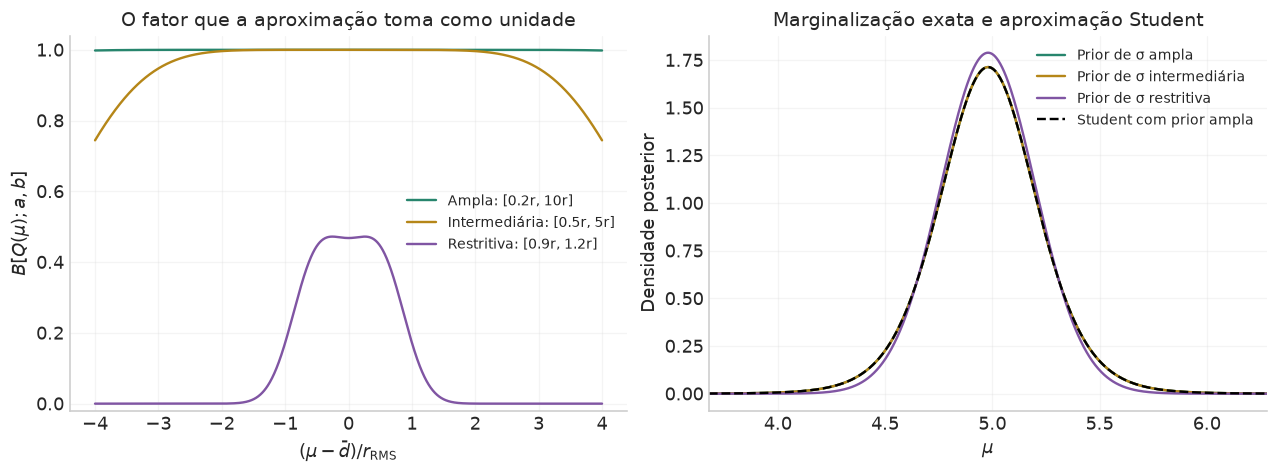

,Prior de σ,TV ante Student truncada,Moda,Média,Mediana,IC central 95% inf.,IC central 95% sup.
0,Ampla,0.00000,4.98,4.98,4.98,4.46768,5.49232
1,Intermediária,0.00001,4.98,4.98,4.98,4.46770,5.49230
2,Restritiva,0.03726,4.98,4.98,4.98,4.53731,5.42269


TV é metade da integral da diferença absoluta entre as densidades normalizadas.


In [7]:
student_mu=stats.t(df=N-1,loc=dbar,scale=S/np.sqrt(N))
mg=np.linspace(dbar-4*r_rms,dbar+4*r_rms,2401)
p_t=student_mu.pdf(mg)
cenarios=[(.2,10.,'Ampla'),(.5,5.,'Intermediária'),(.9,1.2,'Restritiva')]
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
rows=[]
# A prior de localização é comum a todas as curvas e cobre esta grade.
pt_finito=normalizar(mg,p_t)
for (fa,fb,nome),cor in zip(cenarios,[VERDE,OURO,ROXO]):
    aa,bb=fa*r_rms,fb*r_rms
    pex=normalizar(mg,I_escala(N,q+N*(mg-dbar)**2,aa,bb))
    B=intervalo_gamma(N/2,(q+N*(mg-dbar)**2)/(2*bb*bb),(q+N*(mg-dbar)**2)/(2*aa*aa))
    ax[0].plot((mg-dbar)/r_rms,B,color=cor,label=f'{nome}: [{fa:g}r, {fb:g}r]')
    ax[1].plot(mg,pex,color=cor,label=f'Prior de σ {nome.lower()}')
    rows.append({'Prior de σ':nome,'TV ante Student truncada':.5*integrate.trapezoid(abs(pex-pt_finito),mg),**resumo_grade(mg,pex)})
ax[0].set(xlabel=r'$(\mu-\bar d)/r_{\rm RMS}$',ylabel=r'$B[Q(\mu);a,b]$',title='O fator que a aproximação toma como unidade',ylim=(-.02,1.04))
ax[0].legend()
ax[1].plot(mg,p_t,'--',color='black',label='Student com prior ampla')
ax[1].set(xlabel=r'$\mu$',ylabel='Densidade posterior',title='Marginalização exata e aproximação Student',xlim=(dbar-1.3,dbar+1.3))
ax[1].legend()
figura(fig,'04_limites_finitos_e_student')
tabela(pd.DataFrame(rows),'aproximacao_student')
print('TV é metade da integral da diferença absoluta entre as densidades normalizadas.')
verificar('Normalização da Student em toda a reta',np.isclose(integrate.quad(student_mu.pdf,-np.inf,np.inf)[0],1,atol=1e-9))
verificar('Forma analítica do slide coincide com Student',np.allclose(p_t,
    np.exp(special.gammaln(N/2)-special.gammaln((N-1)/2))/np.sqrt(np.pi)/r_rms
    *(1+(mg-dbar)**2/r_rms**2)**(-N/2)))

No painel esquerdo, a prior ampla produz $B\simeq1$ na região central. A diferença nas caudas pode ser maior em termos relativos, mas seu efeito integrado depende de quanta probabilidade há ali. No painel direito, a prior restritiva impõe uma faixa estreita de ruído e muda a largura posterior da média. A tabela quantifica a diferença global pela distância de variação total (TV): zero corresponde a densidades iguais.

Para enxergar a origem do alargamento, observamos a posterior conjunta. Cada valor de $\sigma$ permite uma faixa de $\mu$; valores maiores permitem faixas mais largas. A marginal soma essas possibilidades, com o peso posterior de cada escala.

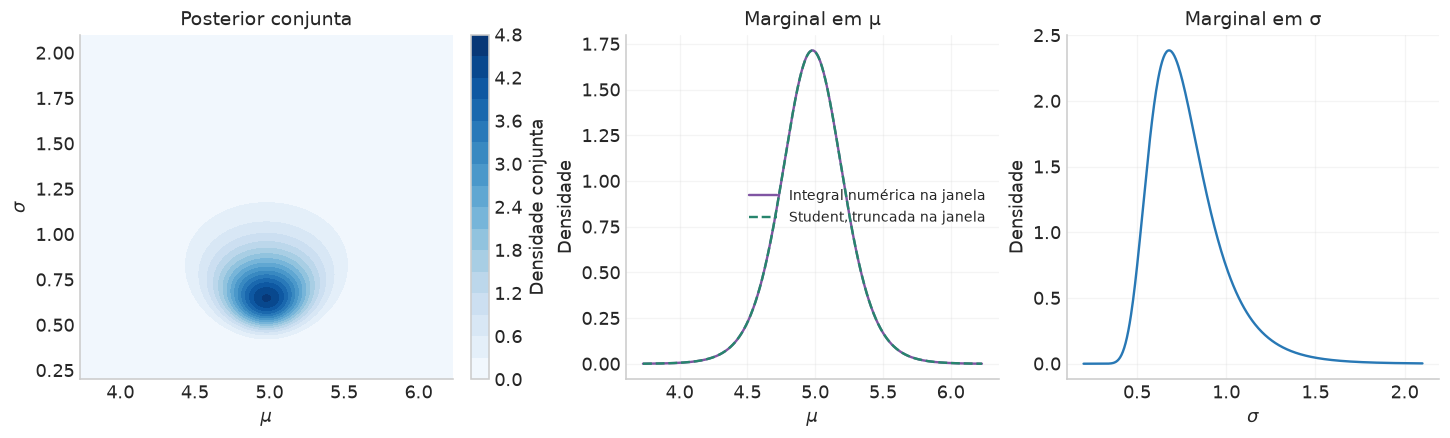

As pequenas diferenças entre as curvas vêm dos limites finitos desta janela.


In [8]:
mm=np.linspace(dbar-1.25,dbar+1.25,601)
ss=np.linspace(.20,2.1,501)
logp=-(N+1)*np.log(ss[:,None])-(q+N*(mm[None,:]-dbar)**2)/(2*ss[:,None]**2)
pjoint=np.exp(logp-logp.max())
pjoint/=integrate.trapezoid(integrate.trapezoid(pjoint,mm,axis=1),ss)
pm=integrate.trapezoid(pjoint,ss,axis=0)
ps=integrate.trapezoid(pjoint,mm,axis=1)
fig,ax=plt.subplots(1,3,figsize=(12.5,3.7),layout='constrained')
cf=ax[0].contourf(mm,ss,pjoint,levels=15,cmap='Blues')
ax[0].set(xlabel=r'$\mu$',ylabel=r'$\sigma$',title='Posterior conjunta')
fig.colorbar(cf,ax=ax[0],label='Densidade conjunta')
ax[1].plot(mm,normalizar(mm,pm),color=ROXO,label='Integral numérica na janela')
ax[1].plot(mm,normalizar(mm,student_mu.pdf(mm)),color=VERDE,ls='--',label='Student, truncada na janela')
ax[1].set(xlabel=r'$\mu$',ylabel='Densidade',title='Marginal em μ');ax[1].legend()
ax[2].plot(ss,normalizar(ss,ps),color=AZUL)
ax[2].set(xlabel=r'$\sigma$',ylabel='Densidade',title='Marginal em σ')
figura(fig,'05_posterior_conjunta_e_marginais')
print('As pequenas diferenças entre as curvas vêm dos limites finitos desta janela.')

## 5. Inferir a própria escala $\sigma$

Vamos inverter a ordem da marginalização. A prior conjunta continua proporcional a $1/\sigma$ e

$$p(\sigma\mid D)\propto\sigma^{-(N+1)}e^{-q/(2\sigma^2)}
\int_L^H e^{-N(\mu-\bar d)^2/(2\sigma^2)}d\mu.$$

A integral em $\mu$ é

$$\sqrt{\frac{2\pi}{N}}\,\sigma\left[
\Phi\!\left(\frac{(H-\bar d)\sqrt N}{\sigma}\right)
-\Phi\!\left(\frac{(L-\bar d)\sqrt N}{\sigma}\right)\right].$$

Com prior de localização ampla, o termo entre colchetes se aproxima de um. O fator $\sigma$ da integração muda $\sigma^{-(N+1)}$ para $\sigma^{-N}$:

$$p(\sigma\mid D)\propto\sigma^{-N}e^{-q/(2\sigma^2)}.$$

### 5.1 Normalização e distribuição da variância

Definimos $\alpha=(N-1)/2$ e $\beta=q/2$. A mesma substituição da seção anterior dá

$$\int_0^\infty\sigma^{-N}e^{-\beta/\sigma^2}d\sigma
=\frac12\beta^{-(N-1)/2}\Gamma\!\left(\frac{N-1}{2}\right).$$

Portanto,

$$\boxed{p(\sigma\mid D)=\frac{2\beta^\alpha}{\Gamma(\alpha)}
\sigma^{-(2\alpha+1)}e^{-\beta/\sigma^2},\quad\sigma>0.}$$

Transformando $v=\sigma^2$, com $d\sigma/dv=1/(2\sqrt v)$,

$$\boxed{p(v\mid D)=\frac{\beta^\alpha}{\Gamma(\alpha)}
v^{-(\alpha+1)}e^{-\beta/v},\quad v>0.}$$

Essa é uma **inversa-Gamma**, na convenção forma $\alpha$ e parâmetro $\beta$ no exponencial $e^{-\beta/v}$. Equivalentemente,

$$\boxed{q/\sigma^2\mid D\sim\chi^2_{N-1}.}$$

A última igualdade é uma distribuição **posterior** para uma transformação do parâmetro. A relação amostral $(N-1)S^2/\sigma^2\sim\chi^2_{N-1}$, estudada no capítulo 6, varia os dados com $\sigma$ fixo. Equivalentemente, $S/\sigma\sim\chi_{N-1}/\sqrt{N-1}$ sob repetições do experimento. A forma qui-quadrado coincide sob as hipóteses e a prior adotadas, e a interpretação acompanha a quantidade que está variando.

### 5.2 Moda e momentos: abrir a conta resolve uma inconsistência da fonte

Derivando o logaritmo da densidade em $\sigma$,

$$\frac{d\log p}{d\sigma}=-\frac N\sigma+\frac q{\sigma^3}=0
\quad\Longrightarrow\quad\widehat\sigma=\sqrt{q/N}=r_{\rm RMS}.$$

Para um momento genérico, a substituição $t=\beta/\sigma^2$ dá

$$\mathbb E[\sigma^k\mid D]
=\frac{\int_0^\infty\sigma^{k-N}e^{-\beta/\sigma^2}d\sigma}
{\int_0^\infty\sigma^{-N}e^{-\beta/\sigma^2}d\sigma}
=\beta^{k/2}\frac{\Gamma[(N-1-k)/2]}{\Gamma[(N-1)/2]},\quad k<N-1.$$

Em particular,

$$\begin{aligned}
\mathbb E[\sigma\mid D]&=\sqrt{q/2}\,
\frac{\Gamma[(N-2)/2]}{\Gamma[(N-1)/2]},&&N>2,\\
\mathbb E[\sigma^2\mid D]&=\boxed{\frac q{N-3}},&&N>3.
\end{aligned}$$

Na última passagem usamos $\Gamma[(N-1)/2]=[(N-3)/2]\Gamma[(N-3)/2]$.

**Conferência com Gregory e slides.** A equação (9.51), p. 226, e os slides 18–20 apresentam $q/(N-1)$ como $\langle\sigma^2\rangle$. A integração da densidade (9.43), com a prior $p(\mu,\sigma)\propto1/\sigma$, produz $q/(N-3)$. O notebook usa o resultado da integral. A identidade correta que envolve a variância amostral é

$$S^2=\frac q{N-1}=\frac1{\mathbb E[1/\sigma^2\mid D]}.$$

Assim, $S^2$, $\mathbb E[\sigma^2\mid D]$, $\mathbb E[\sigma\mid D]$ e a moda resumem aspectos diferentes da posterior. A moda da densidade em $v=\sigma^2$ também muda: $v_{\rm moda}=\beta/(\alpha+1)=q/(N+1)$, pois o jacobiano altera a densidade.

Para antecipar a conexão com ajustes lineares: ao integrar $M$ coeficientes de um modelo identificável com prior de localização ampla, aparece um fator $\sigma^M$. Com o mesmo tratamento da escala, $p(\sigma\mid D)\propto\sigma^{-(N-M+1)}e^{-q_{\min}/(2\sigma^2)}$, dando $\mathbb E[\sigma^2\mid D]=q_{\min}/(N-M-2)$ quando esse momento existe. $q_{\min}/(N-M)$ é o inverso da precisão posterior média. Essa distinção também esclarece a expressão do slide 20.

,Resumo,Valor
0,Moda de σ,0.67941
1,Média posterior de σ,0.78365
2,Raiz da média posterior de σ²,0.81205
3,S = raiz de q/(N−1),0.71616


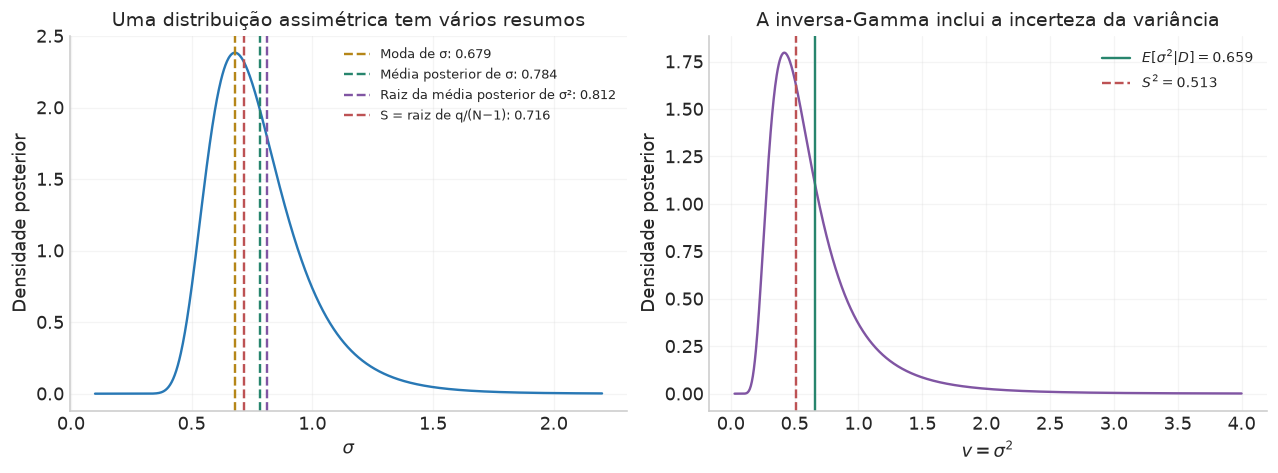

In [9]:
alpha,beta=(N-1)/2,q/2
post_v=stats.invgamma(a=alpha,scale=beta)
def post_sigma(s):
    s=np.asarray(s)
    return 2*s*post_v.pdf(s*s)
E_sigma=np.sqrt(beta)*np.exp(special.gammaln(alpha-.5)-special.gammaln(alpha))
E_v=beta/(alpha-1)
lim_sigma=np.sqrt(post_v.ppf([.025,.975]))
rows=[('Moda de σ',r_rms),('Média posterior de σ',E_sigma),
      ('Raiz da média posterior de σ²',np.sqrt(E_v)),('S = raiz de q/(N−1)',S)]
tabela(pd.DataFrame(rows,columns=['Resumo','Valor']),'resumos_sigma')
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
sg=np.linspace(.1,2.2,1000)
ax[0].plot(sg,post_sigma(sg),color=AZUL)
for (nome,valor),cor in zip(rows,[OURO,VERDE,ROXO,VERMELHO]):
    ax[0].axvline(valor,color=cor,ls='--',label=f'{nome}: {valor:.3f}')
ax[0].set(xlabel=r'$\sigma$',ylabel='Densidade posterior',title='Uma distribuição assimétrica tem vários resumos')
ax[0].legend(fontsize=8)
vg2=np.linspace(.03,4,1000)
ax[1].plot(vg2,post_v.pdf(vg2),color=ROXO)
ax[1].axvline(post_v.mean(),color=VERDE,label=fr'$E[\sigma^2|D]={E_v:.3f}$')
ax[1].axvline(S*S,color=VERMELHO,ls='--',label=fr'$S^2={S*S:.3f}$')
ax[1].set(xlabel=r'$v=\sigma^2$',ylabel='Densidade posterior',title='A inversa-Gamma inclui a incerteza da variância')
ax[1].legend()
figura(fig,'06_posterior_da_escala')
verificar('Posterior de σ normalizada',np.isclose(integrate.quad(post_sigma,0,np.inf)[0],1,atol=1e-9))
verificar('Momento de σ² por integração',np.isclose(integrate.quad(lambda s:s*s*post_sigma(s),0,np.inf)[0],q/(N-3),rtol=1e-9))
verificar('Momento de σ por integração',np.isclose(integrate.quad(lambda s:s*post_sigma(s),0,np.inf)[0],E_sigma,rtol=1e-9))
verificar('Inverso da precisão média corresponde a S²',np.isclose(1/(alpha/beta),S*S))

### 5.3 A Student como mistura: uma segunda conferência

Com prior de localização ampla, para cada $\sigma$ fixo temos

$$\mu\mid\sigma,D\sim\mathcal N(\bar d,\sigma^2/N).$$

Misturando essa normal com a posterior de $\sigma$,

$$\begin{aligned}
p(\mu\mid D)&=\int_0^\infty p(\mu\mid\sigma,D)p(\sigma\mid D)\,d\sigma\\
&\propto\int_0^\infty\sigma^{-(N+1)}
 e^{-[q+N(\mu-\bar d)^2]/(2\sigma^2)}d\sigma
\propto[q+N(\mu-\bar d)^2]^{-N/2}.
\end{aligned}$$

Recuperamos a Student por outra ordem de integração. Pela variância total,

$$\operatorname{Var}(\mu\mid D)=\mathbb E[\sigma^2/N\mid D]
+\operatorname{Var}(\bar d\mid D)=\frac{q}{N(N-3)}.$$

O centro condicional é o mesmo para todas as escalas, por isso o segundo termo é zero. Essa identidade também confere o momento da seção anterior.

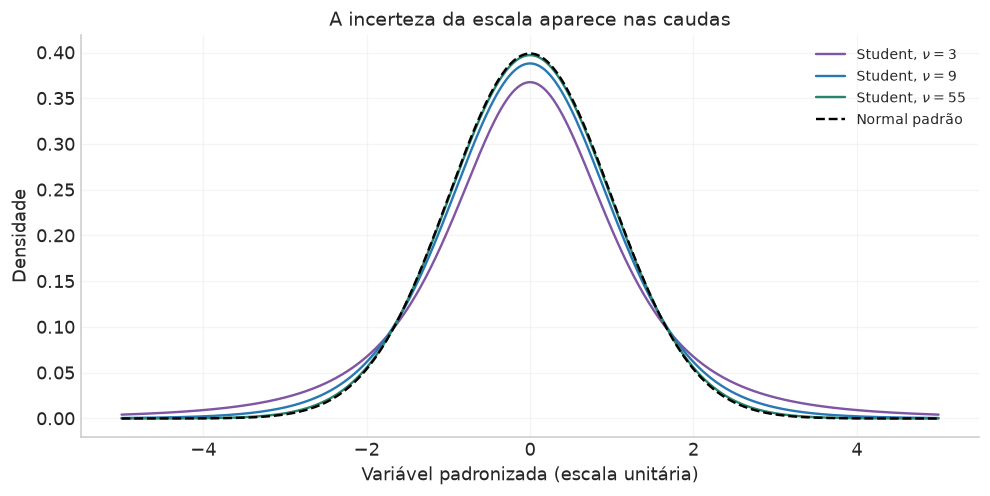

In [10]:
pts=dbar+np.array([-1.,-.4,0.,.4,1.])
p_mix=np.array([integrate.quad(lambda s:stats.norm.pdf(m,dbar,s/np.sqrt(N))*post_sigma(s),0,np.inf)[0] for m in pts])
verificar('Student obtida misturando normais pela posterior da escala',np.allclose(p_mix,student_mu.pdf(pts),rtol=2e-8))
verificar('Variância total da média coincide com a Student',np.isclose(student_mu.var(),E_v/N))
zz=np.linspace(-5,5,1000)
fig,ax=plt.subplots(figsize=(8.5,4.2),layout='constrained')
for nu,cor in [(3,ROXO),(9,AZUL),(55,VERDE)]:
    ax.plot(zz,stats.t.pdf(zz,nu),color=cor,label=fr'Student, $\nu={nu}$')
ax.plot(zz,stats.norm.pdf(zz),'--',color='black',label='Normal padrão')
ax.set(xlabel='Variável padronizada (escala unitária)',ylabel='Densidade',title='A incerteza da escala aparece nas caudas')
ax.legend();figura(fig,'07_student_e_limite_normal')

## 6. Rádio em uma galáxia: dispersão instrumental e adicional

O Gregory apresenta 56 medidas com erro instrumental conhecido $\sigma_{\rm inst}=30$ unidades de fluxo. O objetivo é inferir o nível médio de emissão. Os pontos abaixo foram **recuperados dos marcadores vetoriais da Figura 9.2, p. 223**. São uma digitalização da figura, com precisão gráfica, e ficam incorporados como valores aproximados. O PDF fornecido apresenta essa série em figura; por isso, diferenças pequenas diante dos números arredondados do texto são esperadas.

Primeiro podemos escrever $d_i=\mu+\epsilon_i$, com $\epsilon_i\sim\mathcal N(0,30^2)$: é o **caso de $\sigma$ conhecido e igual**. A dispersão da série é maior do que essa escala instrumental.

Para representar uma componente adicional, fazemos

$$d_i=\mu+\eta_i+\epsilon_i,\qquad
\eta_i\sim\mathcal N(0,\sigma_{\rm extra}^2),\quad
\epsilon_i\sim\mathcal N(0,\sigma_{\rm inst}^2),$$

com as duas contribuições independentes, e independência entre medidas neste modelo. A densidade da soma é uma convolução:

$$p(d_i\mid\mu,\sigma_{\rm extra})=
\int_{-\infty}^{\infty}\mathcal N(z;0,\sigma_{\rm extra}^2)
\mathcal N(d_i;\mu+z,\sigma_{\rm inst}^2)\,dz.$$

Para ver a soma das variâncias, tomamos $y=d_i-\mu$, $A=\sigma_{\rm extra}^2$ e $B=\sigma_{\rm inst}^2$. O expoente contém

$$\frac{z^2}{A}+\frac{(y-z)^2}{B}
=\frac{A+B}{AB}\left(z-\frac{Ay}{A+B}\right)^2
+\frac{y^2}{A+B}.$$

A integral gaussiana em $z$ remove o primeiro termo e normaliza a densidade restante. Obtemos

$$\boxed{d_i\mid\mu,\sigma_{\rm extra}\sim
\mathcal N(\mu,\sigma_{\rm eff}^2),\qquad
\sigma_{\rm eff}^2=30^2+\sigma_{\rm extra}^2.}$$

Estimando a escala efetiva comum, passamos ao **caso de $\sigma$ desconhecido e igual**, com $\sigma_{\rm eff}\geq30$. Vamos seguir a escolha do livro: prior $1/\sigma_{\rm eff}$ entre 30 e 400 e prior uniforme ampla para $\mu$. A prior é especificada na escala **efetiva**. Se quisermos expressá-la em $s=\sigma_{\rm extra}$, o jacobiano dá

$$p(s)\propto\frac{s}{30^2+s^2},\qquad
0\leq s\leq\sqrt{400^2-30^2}.$$

Isso mantém a informação da prior original ao mudar de variável.

N = 56; média digitalizada = 181.909; RMS = 73.872.
Referência arredondada do livro: média ≈ 182 e RMS ≈ 73,8.


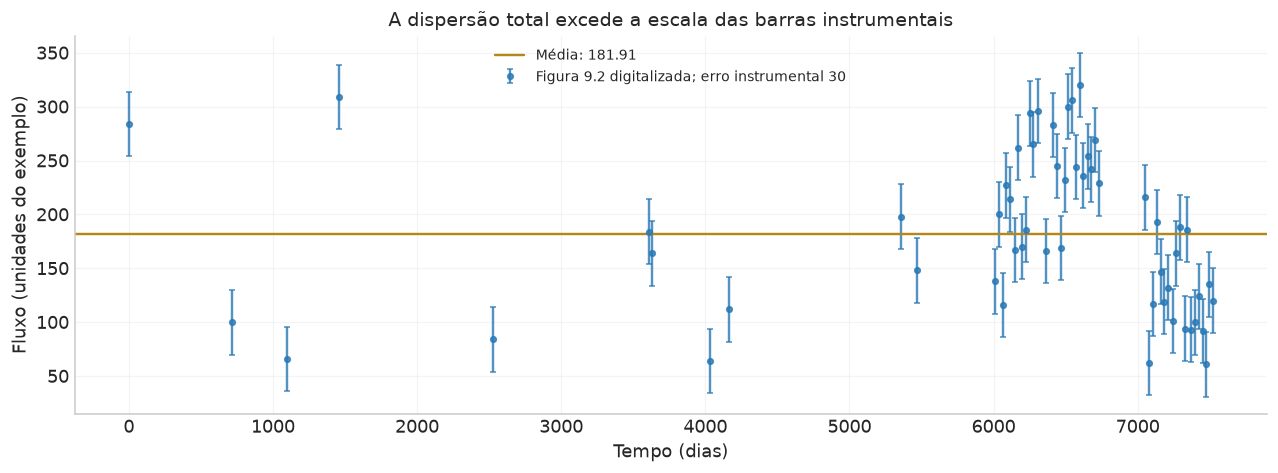

In [11]:
radio = np.array([[0.0, 283.998], [718.0, 100.001], [1097.0, 66.0], [1457.0, 308.998], [2524.0, 84.0], [3607.6, 183.996], [3630.0, 164.0], [4033.0, 63.998], [4161.3, 112.0], [5355.8, 197.999], [5469.1, 147.998], [6012.4, 137.996], [6038.3, 199.995], [6063.2, 115.995], [6089.2, 226.995], [6117.2, 214.0], [6147.3, 166.999], [6172.1, 261.997], [6198.1, 169.996], [6224.8, 185.998], [6252.0, 293.997], [6276.7, 264.997], [6306.8, 295.996], [6361.5, 165.996], [6411.4, 282.995], [6440.5, 245.0], [6467.1, 168.996], [6492.4, 231.998], [6519.1, 299.997], [6544.0, 305.996], [6572.0, 243.997], [6597.9, 319.996], [6623.7, 236.001], [6651.9, 253.999], [6677.8, 242.0], [6705.8, 268.997], [6731.4, 228.998], [7048.7, 215.999], [7075.6, 61.999], [7103.5, 116.999], [7133.6, 192.995], [7164.4, 146.995], [7185.3, 118.997], [7211.2, 131.997], [7244.2, 101.0], [7267.1, 164.0], [7292.0, 187.997], [7324.9, 94.002], [7339.9, 185.998], [7369.9, 92.999], [7398.7, 100.001], [7427.8, 124.001], [7451.8, 91.998], [7473.7, 60.999], [7494.7, 134.999], [7520.5, 119.996]], dtype=float)
# Colunas: tempo em dias e fluxo digitalizado da figura.
t_radio, f_radio = radio.T
Nr, fr_mean, qr = resumo_dados(f_radio)
rr=np.sqrt(qr/Nr)
print(f'N = {Nr}; média digitalizada = {fr_mean:.3f}; RMS = {rr:.3f}.')
print('Referência arredondada do livro: média ≈ 182 e RMS ≈ 73,8.')
fig,ax=plt.subplots(figsize=(11,4),layout='constrained')
ax.errorbar(t_radio,f_radio,yerr=30,fmt='o',ms=3.5,capsize=2,color=AZUL,alpha=.8,label='Figura 9.2 digitalizada; erro instrumental 30')
ax.axhline(fr_mean,color=OURO,label=fr'Média: {fr_mean:.2f}')
ax.set(xlabel='Tempo (dias)',ylabel='Fluxo (unidades do exemplo)',title='A dispersão total excede a escala das barras instrumentais')
ax.legend();figura(fig,'08_radio_dados')
verificar('56 marcadores de rádio incorporados',Nr==56)
verificar('RMS digitalizado próximo ao valor arredondado publicado',abs(rr-73.8)<.2)

### 6.1 Posterior da média e posterior do ruído efetivo

Para a primeira hipótese, $\mu\mid D\simeq\mathcal N(\bar d,30^2/56)$. Para a segunda, usamos a integral finita $I_{56}[Q(\mu);30,400]$, seguida da normalização em $\mu$. Também mostramos a Student de escala ampla para avaliar a aproximação.

A posterior de $\sigma_{\rm eff}$ é a densidade $\sigma^{-56}e^{-q/(2\sigma^2)}$ truncada em $[30,400]$, após integrar a localização com prior ampla. A tabela calculará os momentos sobre esse suporte finito.

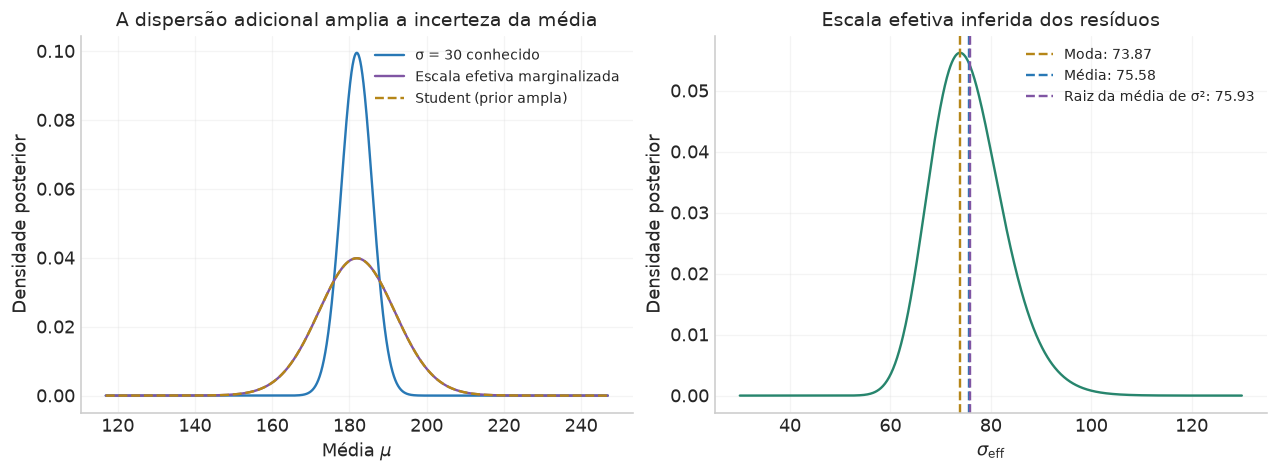

,Tratamento,Moda,Média,Mediana,IC central 95% inf.,IC central 95% sup.
0,σ instrumental conhecido,181.909,181.909,181.909,174.051,189.766
1,σ efetivo marginalizado,181.909,181.909,181.909,161.946,201.871


RMS = 73.872; E[σ_eff] = 75.576; raiz de E[σ_eff²] = 75.934.
Os momentos foram calculados pela posterior; o valor impresso para <σ²> no livro usa a expressão discutida na seção 5.


In [12]:
mr=np.linspace(fr_mean-65,fr_mean+65,1801)
p_known=stats.norm.pdf(mr,fr_mean,30/np.sqrt(Nr))
p_eff=normalizar(mr,I_escala(Nr,qr+Nr*(mr-fr_mean)**2,30,400))
t_r=stats.t(Nr-1,loc=fr_mean,scale=np.sqrt(qr/(Nr-1)/Nr))
vr=stats.invgamma((Nr-1)/2,scale=qr/2)
Zsr=vr.cdf(400**2)-vr.cdf(30**2)
def p_sigma_radio(s):
    s=np.asarray(s)
    return np.where((s>=30)&(s<=400),2*s*vr.pdf(s*s)/Zsr,0.)
sr=np.linspace(30,130,1000)
Er_s=integrate.quad(lambda s:s*p_sigma_radio(s),30,400)[0]
Er_v=integrate.quad(lambda s:s*s*p_sigma_radio(s),30,400)[0]
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].plot(mr,p_known,color=AZUL,label='σ = 30 conhecido')
ax[0].plot(mr,p_eff,color=ROXO,label='Escala efetiva marginalizada')
ax[0].plot(mr,t_r.pdf(mr),color=OURO,ls='--',label='Student (prior ampla)')
ax[0].set(xlabel=r'Média $\mu$',ylabel='Densidade posterior',title='A dispersão adicional amplia a incerteza da média')
ax[0].legend()
ax[1].plot(sr,p_sigma_radio(sr),color=VERDE)
for valor,cor,rot in [(rr,OURO,'Moda'),(Er_s,AZUL,'Média'),(np.sqrt(Er_v),ROXO,'Raiz da média de σ²')]:
    ax[1].axvline(valor,color=cor,ls='--',label=f'{rot}: {valor:.2f}')
ax[1].set(xlabel=r'$\sigma_{\rm eff}$',ylabel='Densidade posterior',title='Escala efetiva inferida dos resíduos')
ax[1].legend(fontsize=8.5)
figura(fig,'09_radio_media_e_ruido')
tr=pd.DataFrame([{'Tratamento':'σ instrumental conhecido',**resumo_grade(mr,p_known)},
                 {'Tratamento':'σ efetivo marginalizado',**resumo_grade(mr,p_eff)}])
tabela(tr,'radio_resumo_media',casas=3)
verificar('Normalização da escala efetiva finita',np.isclose(integrate.quad(p_sigma_radio,30,400)[0],1,atol=1e-9))
print(f'RMS = {rr:.3f}; E[σ_eff] = {Er_s:.3f}; raiz de E[σ_eff²] = {np.sqrt(Er_v):.3f}.')
print('Os momentos foram calculados pela posterior; o valor impresso para <σ²> no livro usa a expressão discutida na seção 5.')

A posterior mais larga atribui aos resíduos a dispersão que o modelo de média constante precisa absorver. A interpretação física dessa dispersão pode envolver variação da fonte, propagação ou outros mecanismos. Identificar um mecanismo ou um padrão temporal exige um modelo correspondente. Aqui estimamos a média e uma escala efetiva, sob a aproximação de flutuações gaussianas independentes.

Também podemos comparar a distribuição de medidas usada em cada tratamento com o histograma. O histograma descreve os fluxos individuais; a posterior de $\mu$ descreve nossa incerteza sobre seu nível médio. Por isso suas larguras têm escalas diferentes.

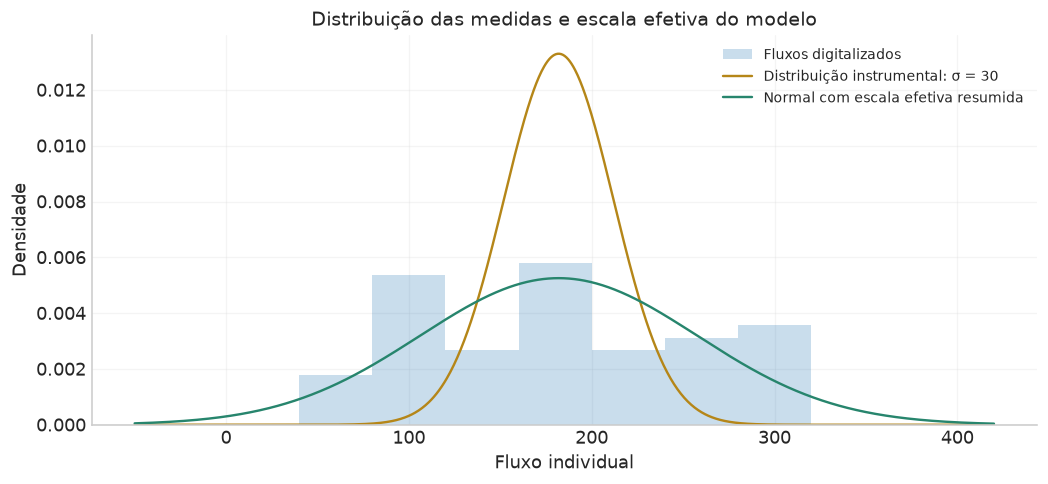

In [13]:
xf=np.linspace(-50,420,1000)
fig,ax=plt.subplots(figsize=(9,4.1),layout='constrained')
ax.hist(f_radio,bins=np.arange(40,361,40),density=True,color=AZUL,alpha=.25,label='Fluxos digitalizados')
ax.plot(xf,stats.norm.pdf(xf,fr_mean,30),color=OURO,label='Distribuição instrumental: σ = 30')
ax.plot(xf,stats.norm.pdf(xf,fr_mean,np.sqrt(Er_v)),color=VERDE,label='Normal com escala efetiva resumida')
ax.set(xlabel='Fluxo individual',ylabel='Densidade',title='Distribuição das medidas e escala efetiva do modelo')
ax.legend();figura(fig,'10_radio_histograma')

## 7. Toxina no rio: comparar modelos e estimar diferenças

Usamos as medidas da **Tabela 7.2, p. 168**, retomadas em Gregory §9.4 e nos slides. A localização 1 é o grupo a montante; a localização 2 é o grupo a jusante. O modelo amostral é

$$d_{ji}=c_j+e_{ji},\qquad
 e_{ji}\overset{\rm ind}{\sim}\mathcal N(0,\sigma_j^2),\qquad j=1,2.$$

Assumimos independência dentro de cada grupo e entre os grupos, condicionada nos parâmetros. $c_j$ é o nível médio da população modelada; $\sigma_j$ inclui a dispersão descrita pelo modelo de cada local.

Definimos $n_j$, $\bar d_j$ e $q_j=\sum_i(d_{ji}-\bar d_j)^2$. Nesta parte, $N=n_1+n_2$ representa o total dos dois grupos. A diferença observada das médias é $\bar d_1-\bar d_2$. A razão dos desvios padrão amostrais é um resumo inicial. A inferência posterior propagará a incerteza de ambos os grupos.

,Grupo,n,Média (ppm),q (ppm²),S (ppm)
0,Montante,12,10.31667,52.13667,2.17708
1,Jusante,8,8.58750,11.46875,1.28000
2,Reunidos,20,9.62500,77.95750,2.02559


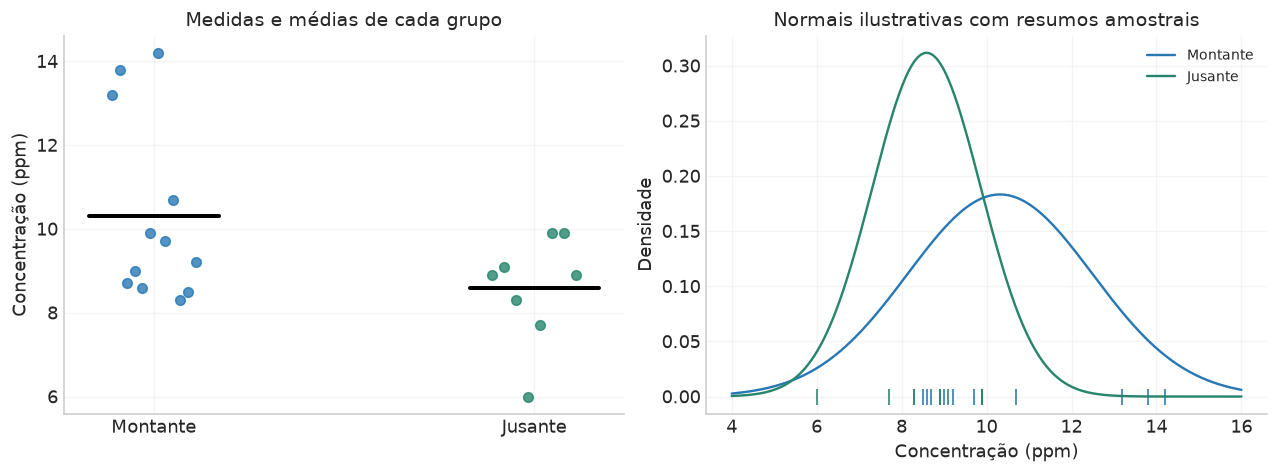

Diferença amostral: 1.729167 ppm; razão S1/S2: 1.700851.


In [14]:
D1=np.array([13.2,13.8,8.7,9.0,8.6,9.9,14.2,9.7,10.7,8.3,8.5,9.2])
D2=np.array([8.9,9.1,8.3,6.0,7.7,9.9,9.9,8.9])
n1,m1,q1=resumo_dados(D1)
n2,m2,q2=resumo_dados(D2)
nt,mt,qt=resumo_dados(np.r_[D1,D2])
resumos=pd.DataFrame([{'Grupo':nome,'n':n,'Média (ppm)':m,'q (ppm²)':qj,'S (ppm)':np.sqrt(qj/(n-1))}
                     for nome,(n,m,qj) in [('Montante',resumo_dados(D1)),('Jusante',resumo_dados(D2)),('Reunidos',resumo_dados(np.r_[D1,D2]))]])
tabela(resumos,'toxina_dados')
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for j,x,cor in [(0,D1,AZUL),(1,D2,VERDE)]:
    offsets=np.linspace(-.11,.11,len(x))
    ax[0].scatter(j+offsets,x,color=cor,alpha=.8)
    ax[0].plot([j-.17,j+.17],[x.mean(),x.mean()],color='black',lw=2.5)
ax[0].set(xticks=[0,1],xticklabels=['Montante','Jusante'],ylabel='Concentração (ppm)',title='Medidas e médias de cada grupo')
z=np.linspace(4,16,500)
for x,cor,nome in [(D1,AZUL,'Montante'),(D2,VERDE,'Jusante')]:
    ax[1].plot(z,stats.norm.pdf(z,x.mean(),x.std(ddof=1)),color=cor,label=nome)
    ax[1].plot(x,np.zeros(len(x)),'|',color=cor,ms=10)
ax[1].set(xlabel='Concentração (ppm)',ylabel='Densidade',title='Normais ilustrativas com resumos amostrais')
ax[1].legend();figura(fig,'11_toxina_dados')
print(f'Diferença amostral: {m1-m2:.6f} ppm; razão S1/S2: {np.sqrt(q1/(n1-1))/np.sqrt(q2/(n2-1)):.6f}.')

### 7.1 Quatro hipóteses explícitas

Seguindo o livro, $C$ representa uma média comum e $S$ uma escala comum. As barras indicam o modelo que permite valores independentes para cada grupo.

| Modelo | Relação entre as médias | Relação entre as escalas | Parâmetros integrados |
|:--|:--|:--|:--|
| $M_{00}=C,S$ | $c_1=c_2=c$ | $\sigma_1=\sigma_2=\sigma$ | $c,\sigma$ |
| $M_{10}=\bar C,S$ | $c_1,c_2$ livres | $\sigma_1=\sigma_2=\sigma$ | $c_1,c_2,\sigma$ |
| $M_{01}=C,\bar S$ | $c_1=c_2=c$ | $\sigma_1,\sigma_2$ livres | $c,\sigma_1,\sigma_2$ |
| $M_{11}=\bar C,\bar S$ | $c_1,c_2$ livres | $\sigma_1,\sigma_2$ livres | $c_1,c_2,\sigma_1,\sigma_2$ |

“Livres” significa que os parâmetros podem assumir valores distintos dentro da prior contínua. A igualdade exata tem probabilidade zero dentro desse modelo contínuo. Sua probabilidade positiva será atribuída pelo modelo separado que impõe a igualdade.

Adotamos $P(M_k)=1/4$, a mesma prior uniforme $1/R$ em $[L,H]$ para cada média livre e a mesma prior $1/[\sigma\ell]$ em $[a,b]$ para cada escala livre, com $R=H-L$ e $\ell=\log(b/a)$.

Para cada modelo,

$$Z_k=\int L_k(\theta_k)p(\theta_k\mid M_k)\,d\theta_k,\qquad
P(M_k\mid D)=\frac{P(M_k)Z_k}{\sum_lP(M_l)Z_l}.$$

$Z_k$ é a **evidência**: uma média da likelihood sob a prior do modelo. A soma no denominador integra o espaço discreto dos modelos. O aumento de flexibilidade vem acompanhado da média sobre o volume a priori dos parâmetros adicionais.

### 7.2 Abrir as quatro evidências

Para cada grupo,

$$L_j(c,s)=(2\pi)^{-n_j/2}s^{-n_j}
\exp\!\left[-\frac{q_j+n_j(c-\bar d_j)^2}{2s^2}\right].$$

Assim,

$$\begin{aligned}
Z_{00}&=\frac1{R\ell}\int_a^b\frac{ds}{s}\int_L^H L_1(c,s)L_2(c,s)dc,\\
Z_{10}&=\frac1{R^2\ell}\int_a^b\frac{ds}{s}
\left[\int_L^H L_1(c_1,s)dc_1\right]
\left[\int_L^H L_2(c_2,s)dc_2\right],\\
Z_{01}&=\frac1{R\ell^2}\int_a^b\!\int_a^b\frac{ds_1ds_2}{s_1s_2}
\int_L^H L_1(c,s_1)L_2(c,s_2)dc,\\
Z_{11}&=\frac1{R^2\ell^2}
\left[\int_a^b\frac{ds_1}{s_1}\int_L^H L_1(c_1,s_1)dc_1\right]
\left[\int_a^b\frac{ds_2}{s_2}\int_L^H L_2(c_2,s_2)dc_2\right].
\end{aligned}$$

Todos os fatores das priors permanecem aqui, porque os modelos contêm números distintos de parâmetros.

### 7.3 Reduzir as dimensões pelas integrais gaussianas

Definimos a probabilidade normal entre bordas

$$A(m,u;L,H)=\Phi[(H-m)/u]-\Phi[(L-m)/u].$$

Integrando uma média de grupo,

$$B_j(s)=\int_L^H L_j(c,s)dc
=(2\pi)^{-n_j/2}s^{-n_j}e^{-q_j/(2s^2)}
\sqrt{2\pi}\frac{s}{\sqrt{n_j}}A(\bar d_j,s/\sqrt{n_j};L,H).$$

Para a média comum e escalas distintas, definimos $w_j=n_j/s_j^2$, $W=w_1+w_2$ e $m_w=(w_1\bar d_1+w_2\bar d_2)/W$. Completando o quadrado,

$$\sum_{j=1}^2\frac{q_j+n_j(c-\bar d_j)^2}{s_j^2}
=W(c-m_w)^2+\frac{q_1}{s_1^2}+\frac{q_2}{s_2^2}
+\frac{(\bar d_1-\bar d_2)^2}{s_1^2/n_1+s_2^2/n_2}.$$

Chamamos os três últimos termos de $K(s_1,s_2)$. Logo,

$$B_{12}(s_1,s_2)=\int_L^H L_1(c,s_1)L_2(c,s_2)dc
=(2\pi)^{-N/2}s_1^{-n_1}s_2^{-n_2}e^{-K/2}
\sqrt{\frac{2\pi}{W}}A(m_w,W^{-1/2};L,H).$$

Essa expressão vale também para $s_1=s_2$, recuperando o modelo dos dados reunidos. Por fim, $\eta=\log s$ fornece $ds/s=d\eta$. As integrais restantes têm uma ou duas dimensões e podem ser calculadas por quadratura determinística em intervalos finitos.

A quadratura de Gauss–Legendre aproxima $\int_a^bf(x)dx$ por $\sum_iw_if(x_i)$. Os nós e pesos são transformados do intervalo $[-1,1]$ para $[a,b]$. Vamos conferir a estabilidade aumentando a quantidade de nós e comparar uma evidência com uma rota de integração diferente.

In [15]:
def quadratura_gl(a,b,k=100):
    z,w=leggauss(k)
    return a+(z+1)*(b-a)/2, w*(b-a)/2

def A_normal(m,u,lo,hi):
    return special.ndtr((hi-m)/u)-special.ndtr((lo-m)/u)

def B_grupo(n,m,qj,s,lo,hi):
    """Integral da likelihood de um grupo sobre sua média, sem a prior de c."""
    u=s/np.sqrt(n)
    return (2*np.pi)**(-n/2)*s**(-n)*np.exp(-qj/(2*s*s))*np.sqrt(2*np.pi)*u*A_normal(m,u,lo,hi)

def B_comum(s1,s2,lo,hi):
    """Integral do produto L1 L2 sobre uma média comum."""
    w1,w2=n1/s1**2,n2/s2**2
    Wc=w1+w2
    mc=(w1*m1+w2*m2)/Wc
    K=q1/s1**2+q2/s2**2+(m1-m2)**2/(1/w1+1/w2)
    return (2*np.pi)**(-nt/2)*s1**(-n1)*s2**(-n2)*np.exp(-K/2)*np.sqrt(2*np.pi/Wc)*A_normal(mc,1/np.sqrt(Wc),lo,hi)

def evidencias(lo,hi,a,b,k=100):
    eta,ws=quadratura_gl(np.log(a),np.log(b),k)
    s=np.exp(eta)
    R,ell=hi-lo,np.log(b/a)
    B1=B_grupo(n1,m1,q1,s,lo,hi)
    B2=B_grupo(n2,m2,q2,s,lo,hi)
    Z00=ws@B_grupo(nt,mt,qt,s,lo,hi)/(R*ell)
    Z10=ws@(B1*B2)/(R*R*ell)
    Z01=np.einsum('i,ij,j',ws,B_comum(s[:,None],s[None,:],lo,hi),ws)/(R*ell*ell)
    Z11=(ws@B1)*(ws@B2)/(R*R*ell*ell)
    return np.array([Z00,Z10,Z01,Z11])

# Caso 4 do Gregory: mesma escolha usada nas figuras principais do exemplo.
limites=(7.,12.,1.,4.)
Z=evidencias(*limites)
prior_modelos=np.full(4,.25)
P=prior_modelos*Z/np.sum(prior_modelos*Z)
nomes=['M00: média e escala comuns','M10: médias livres, escala comum',
       'M01: média comum, escalas livres','M11: médias e escalas livres']
publicado=np.array([.0975,.2892,.1443,.4690])
tabela(pd.DataFrame({'Modelo':nomes,'Evidência Z':[f'{z:.8e}' for z in Z],'Prior':prior_modelos,
                     'Posterior calculada':P,'Gregory (Tabela 9.3)':publicado,
                     'Diferença':P-publicado}),'modelos_toxina',casas=7)
print('Evidências completas, na ordem M00, M10, M01, M11:')
print(np.array2string(Z,precision=9))
verificar('Probabilidades dos quatro modelos somam um',np.isclose(P.sum(),1))
verificar('Probabilidades reproduzem a tabela publicada até 0,0001',np.max(abs(P-publicado))<1e-4)
verificar('Evidências estáveis com 160 nós',np.allclose(Z,evidencias(*limites,k=160),rtol=1e-9))

# Rota independente para Z00: primeiro integrar a escala com Gamma incompleta,
# depois integrar a média. Rescalamos para preservar precisão absoluta no quad.
lo,hi,aa,bb=limites
Z00_outra=integrate.quad(lambda c:(2*np.pi)**(-nt/2)*I_escala(nt,qt+nt*(c-mt)**2,aa,bb)
                       /(hi-lo)/np.log(bb/aa)/Z[0],lo,hi,epsabs=1e-9)[0]*Z[0]
verificar('Z00 por duas ordens independentes de integração',np.isclose(Z00_outra,Z[0],rtol=1e-9))

,Modelo,Evidência Z,Prior,Posterior calculada,Gregory (Tabela 9.3),Diferença
0,M00: média e escala comuns,3.87661948e-20,0.25,0.097579,0.0975,0.000079
1,"M10: médias livres, escala comum",1.14875024e-19,0.25,0.289153,0.2892,-0.000047
2,"M01: média comum, escalas livres",5.73236074e-20,0.25,0.144290,0.1443,-0.000010
3,M11: médias e escalas livres,1.86316849e-19,0.25,0.468979,0.4690,-0.000021


Evidências completas, na ordem M00, M10, M01, M11:
[3.876619482e-20 1.148750244e-19 5.732360742e-20 1.863168494e-19]


As probabilidades calculadas reproduzem a tabela do livro à precisão de seu arredondamento numérico. Para ler os resultados, somamos as hipóteses que respondem à mesma pergunta:

$$\begin{aligned}
P(C\mid D)&=P_{00}+P_{01},& P(\bar C\mid D)&=P_{10}+P_{11},\\
P(S\mid D)&=P_{00}+P_{10},& P(\bar S\mid D)&=P_{01}+P_{11},\\
P(\text{alguma diferença}\mid D)&=1-P_{00}.
\end{aligned}$$

A última pergunta reúne três alternativas. Como cada modelo recebeu prior $1/4$, as odds a priori de “alguma diferença” contra $M_{00}$ são $3:1$. As odds posteriores são aproximadamente $9{,}25:1$. O **fator de Bayes** para a alternativa composta é a razão entre essas odds: aproximadamente $3{,}08$.

Podemos obter o mesmo fator definindo $H_1=\{M_{10},M_{01},M_{11}\}$ com pesos condicionais iguais a $1/3$. Sua evidência é $Z_{H_1}=(Z_{10}+Z_{01}+Z_{11})/3$. Com prior $P(H_1)=P(M_{00})=1/2$, a probabilidade posterior de alguma diferença muda para cerca de $75{,}5\%$. Os dados e as evidências individuais são os mesmos; mudou a alocação de probabilidade entre as hipóteses.

Essas probabilidades descrevem diferenças entre populações no modelo gaussiano especificado. Uma interpretação causal sobre a instalação industrial depende também do desenho da coleta, da comparabilidade dos locais e de outras fontes de variação.

,Pergunta,Probabilidade
0,Médias livres (C̄),0.75813
1,Escalas livres (S̄),0.61327
2,Alguma diferença,0.90242
3,Médias comuns (C),0.24187
4,Escalas comuns (S),0.38673


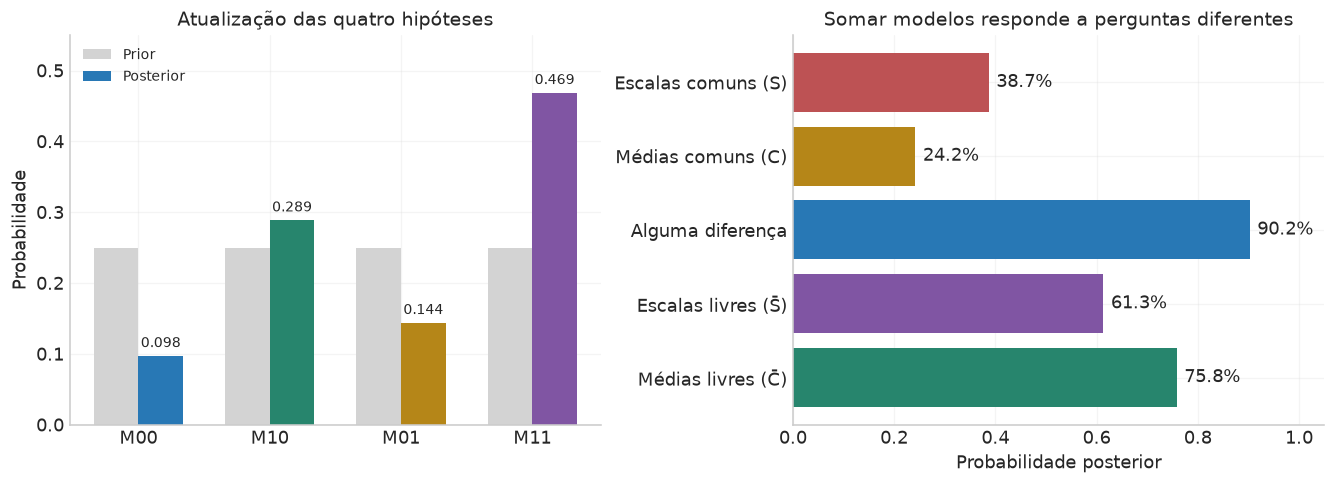

Odds posteriores: 9.24815; fator de Bayes composto: 3.08272.
Com prior 1/2 para cada hipótese agregada: P(alguma diferença|D) = 0.75506.


In [17]:
P_C=P[0]+P[2]
P_S=P[0]+P[1]
P_diff=1-P[0]
odds_diff=P_diff/P[0]
BF_composto=odds_diff/3
p_composto_prior_meio=BF_composto/(1+BF_composto)
perguntas=pd.DataFrame({'Pergunta':['Médias livres (C̄)','Escalas livres (S̄)','Alguma diferença','Médias comuns (C)','Escalas comuns (S)'],
                        'Probabilidade':[1-P_C,1-P_S,P_diff,P_C,P_S]})
tabela(perguntas,'perguntas_toxina')
fig,ax=plt.subplots(1,2,figsize=(11.5,4.1),layout='constrained')
xx=np.arange(4)
ax[0].bar(xx-.17,prior_modelos,width=.34,color='lightgray',label='Prior')
ax[0].bar(xx+.17,P,width=.34,color=[AZUL,VERDE,OURO,ROXO],label='Posterior')
for j,p in enumerate(P):ax[0].text(j+.17,p+.012,f'{p:.3f}',ha='center',fontsize=9)
ax[0].set(xticks=xx,xticklabels=['M00','M10','M01','M11'],ylabel='Probabilidade',ylim=(0,.55),title='Atualização das quatro hipóteses')
ax[0].legend()
ax[1].barh(perguntas['Pergunta'],perguntas['Probabilidade'],color=[VERDE,ROXO,AZUL,OURO,VERMELHO])
ax[1].set(xlabel='Probabilidade posterior',xlim=(0,1.05),title='Somar modelos responde a perguntas diferentes')
for j,p in enumerate(perguntas['Probabilidade']):ax[1].text(p+.015,j,f'{100*p:.1f}%',va='center')
figura(fig,'12_toxina_modelos')
print(f'Odds posteriores: {odds_diff:.5f}; fator de Bayes composto: {BF_composto:.5f}.')
print(f'Com prior 1/2 para cada hipótese agregada: P(alguma diferença|D) = {p_composto_prior_meio:.5f}.')

### 7.4 Sensibilidade aos quatro intervalos de prior do Gregory

Vamos repetir a comparação com as quatro escolhas da Tabela 9.2. As médias têm unidades de ppm e as escalas também. Todos os limites ficam explícitos.

Ampliar uma prior distribui sua probabilidade por mais possibilidades. Um modelo que ocupa apenas uma parte pequena desse espaço recebe uma evidência média menor. Como os modelos contêm números diferentes de médias e escalas livres, a alteração dos intervalos afeta seus fatores de volume de maneiras distintas. Isso explica a sensibilidade das probabilidades de modelo.

,Caso,L,H,a,b,P00,P10,P01,P11,P(médias livres),P(escalas livres),P(alguma diferença),Odds diferença
0,1,2.0,18.0,0.4,10.0,0.2931,0.2760,0.2091,0.2218,0.4978,0.4309,0.7069,2.4121
1,2,7.0,12.0,0.4,10.0,0.1417,0.4196,0.1011,0.3376,0.7573,0.4387,0.8583,6.0595
2,3,2.0,18.0,1.0,4.0,0.2022,0.1905,0.2990,0.3083,0.4988,0.6073,0.7978,3.9453
3,4,7.0,12.0,1.0,4.0,0.0976,0.2892,0.1443,0.4690,0.7581,0.6133,0.9024,9.2481


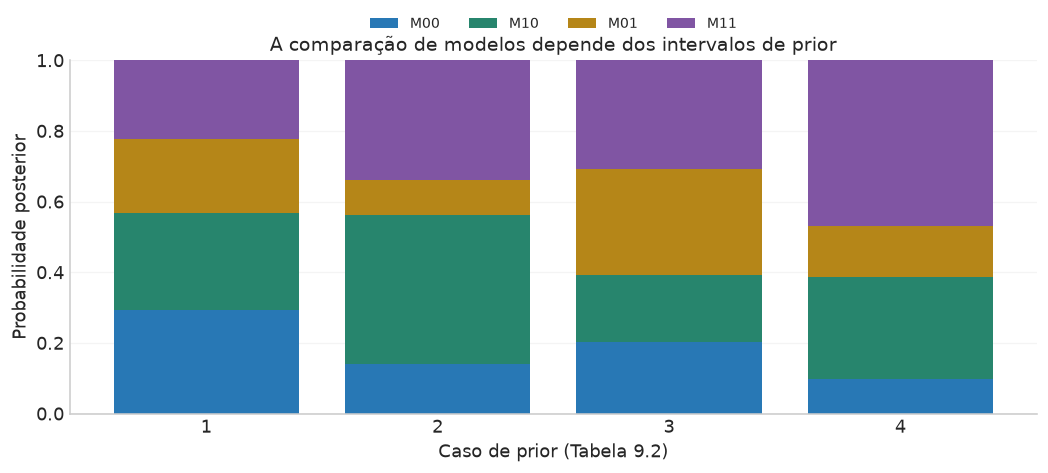

In [18]:
casos=[(2.,18.,.4,10.),(7.,12.,.4,10.),(2.,18.,1.,4.),(7.,12.,1.,4.)]
P_casos=[]
linhas=[]
for j,lim in enumerate(casos,1):
    z=evidencias(*lim)
    p=z/z.sum();P_casos.append(p)
    linhas.append({'Caso':j,'L':lim[0],'H':lim[1],'a':lim[2],'b':lim[3],
                   'P00':p[0],'P10':p[1],'P01':p[2],'P11':p[3],
                   'P(médias livres)':p[1]+p[3],
                   'P(escalas livres)':p[2]+p[3],
                   'P(alguma diferença)':1-p[0],'Odds diferença':(1-p[0])/p[0]})
sensibilidade=pd.DataFrame(linhas)
tabela(sensibilidade,'sensibilidade_priors',casas=4)
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
base=np.zeros(4)
for k,(cor,rot) in enumerate(zip([AZUL,VERDE,OURO,ROXO],['M00','M10','M01','M11'])):
    vals=np.array(P_casos)[:,k]
    ax.bar(np.arange(1,5),vals,bottom=base,color=cor,label=rot)
    base+=vals
ax.set(xticks=np.arange(1,5),xlabel='Caso de prior (Tabela 9.2)',ylabel='Probabilidade posterior',title='A comparação de modelos depende dos intervalos de prior',ylim=(0,1))
ax.legend(ncol=4,loc='upper center',bbox_to_anchor=(.5,1.16))
figura(fig,'13_sensibilidade_dos_modelos')
publicado_casos=np.array([[.293,.276,.209,.222],[.141,.420,.101,.338],[.202,.190,.299,.308],[.098,.289,.144,.469]])
verificar('Quatro casos reproduzem a Tabela 9.4 dentro de 0,001',np.max(abs(np.array(P_casos)-publicado_casos))<.001)

## 8. Quanto diferem as médias? Transformação e marginalização

Definimos $\delta=c_1-c_2$ e $\gamma=c_1+c_2$. Invertendo,

$$c_1=\frac{\gamma+\delta}{2},\qquad c_2=\frac{\gamma-\delta}{2},\qquad
\left|\frac{\partial(c_1,c_2)}{\partial(\delta,\gamma)}\right|
=\left|\det\begin{pmatrix}1/2&1/2\\-1/2&1/2\end{pmatrix}\right|=\frac12.$$

Se cada média está em $[L,H]$, então $\delta\in[-R,R]$ e

$$2L+|\delta|\leq\gamma\leq2H-|\delta|.$$

O quadrado no plano $(c_1,c_2)$ vira um losango. A prior induzida da diferença é triangular: integrar a densidade $1/(2R^2)$ sobre o comprimento permitido de $\gamma$ produz

$$p(\delta)=\frac{R-|\delta|}{R^2}\mathbf1_{[-R,R]}(\delta).$$

Isso conserva a prior original sobre as duas médias livres. Atribuir diretamente uma prior uniforme à diferença seria uma escolha diferente.

### 8.1 Escala comum, médias livres: $M_{10}$

Para calcular a densidade de $\delta$, usamos $u=c_2$, de modo que $c_1=u+\delta$ e o jacobiano é um. O suporte é

$$u_-(\delta)=\max(L,L-\delta),\qquad
u_+(\delta)=\min(H,H-\delta).$$

Com $d=\bar d_1-\bar d_2$ e $\kappa=n_1n_2/N$,

$$\begin{aligned}
Q(u,\delta)&=q_1+q_2+n_1(u+\delta-\bar d_1)^2+n_2(u-\bar d_2)^2\\
&=q_1+q_2+\kappa(\delta-d)^2+N[u-u_0(\delta)]^2,\\
u_0(\delta)&=\frac{n_1(\bar d_1-\delta)+n_2\bar d_2}{N}.
\end{aligned}$$

Integrando $u$ pela integral normal já conhecida, obtemos a densidade não normalizada

$$h_{10}(\delta)=\frac1{R^2\ell}\int_a^b\frac{ds}{s}
(2\pi)^{-N/2}s^{-N}
 e^{-[q_1+q_2+\kappa(\delta-d)^2]/(2s^2)}
\sqrt{\frac{2\pi}{N}}s\,
A[u_0(\delta),s/\sqrt N;u_-(\delta),u_+(\delta)].$$

A densidade desejada é $g_{10}(\delta)=h_{10}(\delta)/Z_{10}$.

No limite de priors amplas, a integração de $s$ deixa uma potência de
$T(\delta)=q_1+q_2+\kappa(\delta-d)^2$. O expoente é $-(N-1)/2$, porque integramos uma média comum auxiliar. Comparando com a Student,

$$\delta\mid D,M_{10}\simeq t_{N-2}\left(d,
 s_p\sqrt{\frac1{n_1}+\frac1{n_2}}\right),\qquad
s_p^2=\frac{q_1+q_2}{N-2}.$$

As curvas numéricas manterão os limites finitos originais; a Student servirá como conferência da forma aproximada.

### 8.2 Escalas e médias livres: $M_{11}$

Nesse modelo, os grupos são independentes também a posteriori, pois likelihood e prior se fatoram. Para cada grupo,

$$p_j(c\mid D_j)=\frac{G_j(c)}{RZ_j},\qquad
G_j(c)=\frac{(2\pi)^{-n_j/2}}\ell
 I_{n_j}[q_j+n_j(c-\bar d_j)^2;a,b],$$

onde $Z_j=R^{-1}\int_L^HG_j(c)dc$ e $Z_{11}=Z_1Z_2$. Portanto,

$$\boxed{g_{11}(\delta)=\int_{u_-(\delta)}^{u_+(\delta)}
p_1(u+\delta\mid D_1)p_2(u\mid D_2)du.}$$

É a convolução da posterior da primeira média com a posterior refletida da segunda. Ela propaga as duas incertezas e representa a versão bayesiana do problema de Behrens–Fisher. Sua forma geral é uma convolução de distribuições; cada posterior individual se aproxima de uma Student no limite amplo.

### 8.3 Reproduzir também a escolha de prior do Apêndice C

As equações (C.30)–(C.31) atribuem **novas priors uniformes independentes** a $\delta\in[-R,R]$ e $\gamma\in[2L,2H]$. O suporte passa a ser um retângulo em $(\delta,\gamma)$. A transformação exata das priors originais produz o losango e a prior triangular de $\delta$ que acabamos de deduzir.

Para reproduzir a construção do apêndice, calculamos

$$\begin{aligned}
g^{B}_{10}(\delta)&\propto\int_{2L}^{2H}d\gamma\int_a^b\frac{ds}{s}
L_1\!\left(\frac{\gamma+\delta}{2},s\right)L_2\!\left(\frac{\gamma-\delta}{2},s\right),\\
g^{B}_{11}(\delta)&\propto\int_{2L}^{2H}G_1\!\left(\frac{\gamma+\delta}{2}\right)
G_2\!\left(\frac{\gamma-\delta}{2}\right)d\gamma.
\end{aligned}$$

Cada curva é normalizada sobre $[-R,R]$. No primeiro caso, a substituição $u=(\gamma-\delta)/2$ fornece $d\gamma=2du$ e bordas $L-\delta/2$ e $H-\delta/2$; a mesma integral normal da seção 8.1 resolve a integração em $u$. No segundo, usamos as integrais de escala $G_j$ e uma quadratura em $\gamma$. O sobrescrito $B$ identifica essa etapa com as novas priors do livro. A comparação permite acompanhar as duas escolhas sem misturar seus suportes.

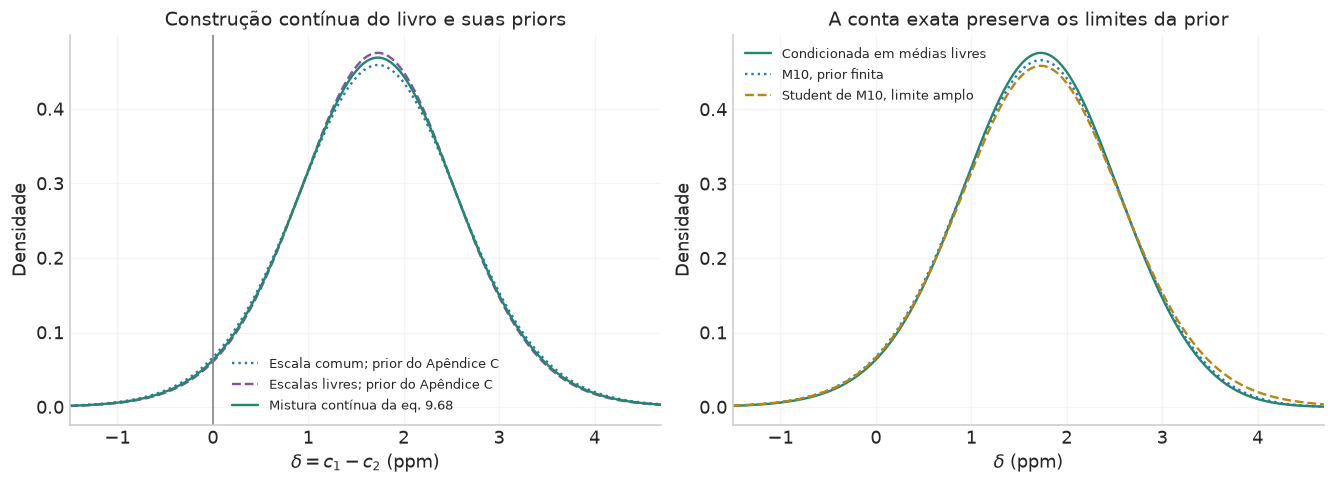

,Curva,Moda,Média,Mediana,IC central 95% inf.,IC central 95% sup.
0,"M10, priors originais",1.72778,1.69672,1.71097,-0.07972,3.37994
1,"M11, priors originais",1.72778,1.69986,1.71376,-0.01807,3.32252
2,Mistura contínua do livro,1.72778,1.72725,1.72860,-0.03678,3.48614
3,Condicional em médias livres,1.72778,1.69866,1.71271,-0.04206,3.34461


In [19]:
def pdf_media_grupo(c,n,m,qj,lo,hi,a,b):
    # Z_j por quadratura na escala; a forma em c usa a Gamma incompleta.
    eta,ww=quadratura_gl(np.log(a),np.log(b),100)
    Zj=ww@B_grupo(n,m,qj,np.exp(eta),lo,hi)/(hi-lo)/np.log(b/a)
    c=np.asarray(c)
    p=(2*np.pi)**(-n/2)*I_escala(n,qj+n*(c-m)**2,a,b)/(hi-lo)/np.log(b/a)/Zj
    return np.where((c>=lo)&(c<=hi),p,0.)

def densidades_delta(lim,k_delta=1801):
    lo,hi,a,b=lim;R=hi-lo;ell=np.log(b/a)
    Zloc=evidencias(*lim)
    delta=np.linspace(-R,R,k_delta)
    eta,ww=quadratura_gl(np.log(a),np.log(b),110)
    s=np.exp(eta)[None,:]
    dm=delta[:,None]
    umin=np.maximum(lo,lo-dm);umax=np.minimum(hi,hi-dm)
    u0=(n1*(m1-dm)+n2*m2)/nt
    T=q1+q2+n1*n2/nt*(dm-(m1-m2))**2
    h=(2*np.pi)**(-nt/2)*s**(-nt)*np.exp(-T/(2*s*s))*np.sqrt(2*np.pi/nt)*s
    h*=A_normal(u0,s/np.sqrt(nt),umin,umax)
    g10=(h@ww)/(R*R*ell)/Zloc[1]
    # Integral em u por Gauss-Legendre, com bordas dependentes de delta.
    z,w=leggauss(140)
    uu=umin+(z[None,:]+1)*(umax-umin)/2
    wu=w[None,:]*(umax-umin)/2
    g11=np.sum(wu*pdf_media_grupo(uu+dm,n1,m1,q1,*lim)
                 *pdf_media_grupo(uu,n2,m2,q2,*lim),axis=1)
    verificar(f'Área g10 delta {lim}',np.isclose(integrate.trapezoid(g10,delta),1,atol=3e-6))
    verificar(f'Área g11 delta {lim}',np.isclose(integrate.trapezoid(g11,delta),1,atol=3e-6))
    return delta,normalizar(delta,g10),normalizar(delta,g11)

def delta_prior_apendice(lim,k_delta=1801):
    """Priors independentes em delta e gamma das equações C.30–C.31."""
    lo,hi,a,b=lim;R=hi-lo;ell=np.log(b/a)
    dd=np.linspace(-R,R,k_delta)
    dm=dd[:,None]
    eta,ww=quadratura_gl(np.log(a),np.log(b),110)
    s=np.exp(eta)[None,:]
    umin=lo-dm/2;umax=hi-dm/2
    u0=(n1*(m1-dm)+n2*m2)/nt
    T=q1+q2+n1*n2/nt*(dm-(m1-m2))**2
    h=(2*np.pi)**(-nt/2)*s**(-nt)*np.exp(-T/(2*s*s))*np.sqrt(2*np.pi/nt)*s
    h*=A_normal(u0,s/np.sqrt(nt),umin,umax)
    h10=2*(h@ww)
    gamma,wg=quadratura_gl(2*lo,2*hi,180)
    c1=(gamma[None,:]+dm)/2
    c2=(gamma[None,:]-dm)/2
    G1=(2*np.pi)**(-n1/2)*I_escala(n1,q1+n1*(c1-m1)**2,a,b)/ell
    G2=(2*np.pi)**(-n2/2)*I_escala(n2,q2+n2*(c2-m2)**2,a,b)/ell
    h11=(G1*G2)@wg
    return dd,normalizar(dd,h10),normalizar(dd,h11)

delta,g10,g11=densidades_delta(limites)
# Reprodução da etapa de estimação do livro, incluindo as novas priors.
delta_B,gb10,gb11=delta_prior_apendice(limites)
g_delta_livro=P_S*gb10+(1-P_S)*gb11
# Densidade condicional coerente com o espaço de quatro modelos: médias livres.
w10=P[1]/(P[1]+P[3])
g_delta_cond=w10*g10+(1-w10)*g11
sp=np.sqrt((q1+q2)/(nt-2))
t_delta=stats.t(nt-2,loc=m1-m2,scale=sp*np.sqrt(1/n1+1/n2))
fig,ax=plt.subplots(1,2,figsize=(11.5,4.1),layout='constrained')
ax[0].plot(delta_B,gb10,color=AZUL,ls=':',label='Escala comum; prior do Apêndice C')
ax[0].plot(delta_B,gb11,color=ROXO,ls='--',label='Escalas livres; prior do Apêndice C')
ax[0].plot(delta_B,g_delta_livro,color=VERDE,label='Mistura contínua da eq. 9.68')
ax[0].axvline(0,color='gray',lw=1)
ax[0].set(xlabel=r'$\delta=c_1-c_2$ (ppm)',ylabel='Densidade',title='Construção contínua do livro e suas priors',xlim=(-1.5,4.7))
ax[0].legend(fontsize=8.3)
ax[1].plot(delta,g_delta_cond,color=VERDE,label='Condicionada em médias livres')
ax[1].plot(delta,g10,color=AZUL,ls=':',label='M10, prior finita')
ax[1].plot(delta,t_delta.pdf(delta),color=OURO,ls='--',label='Student de M10, limite amplo')
ax[1].set(xlabel=r'$\delta$ (ppm)',ylabel='Densidade',title='A conta exata preserva os limites da prior',xlim=(-1.5,4.7))
ax[1].legend(fontsize=8.3)
figura(fig,'14_diferenca_de_medias')
tabela(pd.DataFrame([{'Curva':nome,**resumo_grade(delta,p)} for nome,p in
                     [('M10, priors originais',g10),('M11, priors originais',g11),('Mistura contínua do livro',g_delta_livro),('Condicional em médias livres',g_delta_cond)]]),
       'delta_resumos')

### 8.4 Curvas contínuas e probabilidade de igualdade exata

As curvas anteriores ficam centradas perto de $1{,}73$ ppm e mostram a magnitude de uma diferença quando estimamos duas médias livres. Para interpretar a média ponderada desenhada no capítulo, precisamos explicitar a escolha dos pesos.

A equação (9.68) usa $P(S\mid D)$ e $P(\bar S\mid D)$ para combinar as duas soluções contínuas da etapa de estimação com as novas priors. Reproduzimos essa curva como **mistura contínua do livro**. Para fazer a média de modelos preservando as priors originais e condicionando em médias livres, usamos $g_{10}$ e $g_{11}$ e os pesos

$$P(M_{10}\mid\bar C,D)=\frac{P_{10}}{P_{10}+P_{11}},\qquad
P(M_{11}\mid\bar C,D)=\frac{P_{11}}{P_{10}+P_{11}}.$$

Assim,

$$p(\delta\mid\bar C,D)=\frac{P_{10}g_{10}(\delta)+P_{11}g_{11}(\delta)}{P_{10}+P_{11}}.$$

Se a pergunta inclui os modelos com média comum, a distribuição completa é **mista**:

$$\boxed{p(d\delta\mid D)=P(C\mid D)\,\delta_0(d\delta)
+\big[P_{10}g_{10}(\delta)+P_{11}g_{11}(\delta)\big]d\delta.}$$

$\delta_0$ representa uma massa pontual unitária em zero. Seu peso é $P(C\mid D)\simeq0{,}242$. As curvas contínuas se integram a um quando usadas como densidades condicionais; a parte contínua da distribuição completa integra a $P(\bar C\mid D)\simeq0{,}758$.

Essa distinção permite responder separadamente à direção e à existência de uma diferença. Para um limiar prático $\epsilon>0$,

$$P(\delta>\epsilon\mid D)
=P(\bar C\mid D)\int_\epsilon^R p(\delta\mid\bar C,D)\,d\delta.$$

Um limiar em ppm torna a pergunta científica explícita. Por exemplo, “a média a montante supera a de jusante em mais de 1 ppm?” combina magnitude, incerteza e probabilidade dos modelos.

,Limiar ε (ppm),"P(δ > ε | médias livres,D)","P(δ > ε | quatro modelos,D)"
0,0.0,0.97243,0.73723
1,0.5,0.91850,0.69634
2,1.0,0.79864,0.60548
3,2.0,0.36562,0.27719


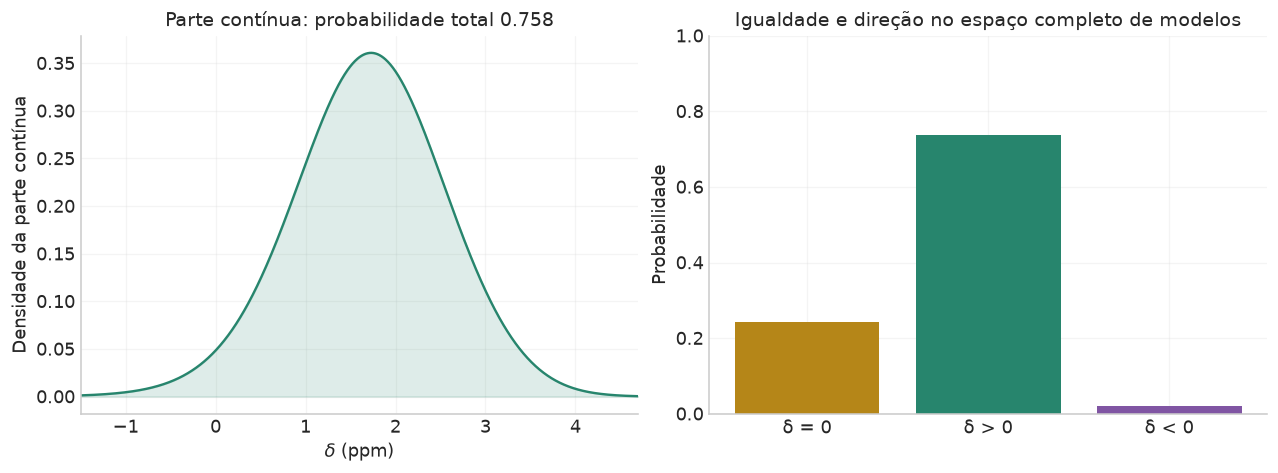

In [20]:
def prob_acima_grade(x,p,limiar):
    # Inserir o limiar evita perder o pequeno trecho entre pontos adjacentes.
    xx=np.r_[limiar,x[x>limiar]]
    return integrate.trapezoid(np.interp(xx,x,p,left=0,right=0),xx)

linhas=[]
for eps in [0.,.5,1.,2.]:
    cond=prob_acima_grade(delta,g_delta_cond,eps)
    linhas.append({'Limiar ε (ppm)':eps,'P(δ > ε | médias livres,D)':cond,
                   'P(δ > ε | quatro modelos,D)':(1-P_C)*cond})
tabela(pd.DataFrame(linhas),'delta_probabilidades')
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].plot(delta,(1-P_C)*g_delta_cond,color=VERDE)
ax[0].fill_between(delta,0,(1-P_C)*g_delta_cond,color=VERDE,alpha=.15)
ax[0].set(xlabel=r'$\delta$ (ppm)',ylabel='Densidade da parte contínua',title=fr'Parte contínua: probabilidade total {1-P_C:.3f}',xlim=(-1.5,4.7))
ax[1].bar(['δ = 0','δ > 0','δ < 0'],[P_C,(1-P_C)*prob_acima_grade(delta,g_delta_cond,0),
    (1-P_C)*(1-prob_acima_grade(delta,g_delta_cond,0))],color=[OURO,VERDE,ROXO])
ax[1].set(ylabel='Probabilidade',ylim=(0,1),title='Igualdade e direção no espaço completo de modelos')
figura(fig,'15_delta_distribuicao_mista')
verificar('Massa da distribuição completa de delta',np.isclose(P_C+(1-P_C)*integrate.trapezoid(g_delta_cond,delta),1))

## 9. Quanto diferem as escalas? A razão $r=\sigma_1/\sigma_2$

Agora $r$ representa uma **razão de desvios padrão**; a dispersão residual anterior foi escrita como $r_{\rm RMS}$. Escolhemos $s=\sigma_2$, então

$$\sigma_1=rs,\qquad\sigma_2=s,\qquad
\left|\frac{\partial(\sigma_1,\sigma_2)}{\partial(r,s)}\right|
=\left|\det\begin{pmatrix}s&r\\0&1\end{pmatrix}\right|=s.$$

A prior conjunta transformada é

$$p(r,s)=\frac1{(rs)\ell}\frac1{s\ell}\,s
=\frac1{rs\ell^2}.$$

As duas escalas precisam permanecer em $[a,b]$. Logo,

$$a/b\leq r\leq b/a,\qquad
s_-(r)=\max(a,a/r),\quad s_+(r)=\min(b,b/r).$$

A prior marginal induzida também pode ser calculada:

$$p(r)=\frac1{r\ell^2}\int_{s_-(r)}^{s_+(r)}\frac{ds}{s}
=\frac{\ell-|\log r|}{r\ell^2},\qquad |\log r|\leq\ell.$$

O suporte dependente de $r$ e o jacobiano preservam a prior original. Em $\log r$, a densidade tem forma triangular.

### 9.1 Integrar as médias e a escala auxiliar

Para médias livres, usamos $B_1(rs)B_2(s)$; para uma média comum, usamos $B_{12}(rs,s)$. As duas densidades são

$$\begin{aligned}
h_{11}(r)&=\frac1{R^2r\ell^2}
\int_{s_-(r)}^{s_+(r)}B_1(rs)B_2(s)\frac{ds}{s},
&g_{11}^{(r)}(r)&=\frac{h_{11}(r)}{Z_{11}},\\
h_{01}(r)&=\frac1{Rr\ell^2}
\int_{s_-(r)}^{s_+(r)}B_{12}(rs,s)\frac{ds}{s},
&g_{01}^{(r)}(r)&=\frac{h_{01}(r)}{Z_{01}}.
\end{aligned}$$

São exatamente as integrais da transformação, com as médias já eliminadas analiticamente. A nova substituição $\eta=\log s$ fornece as integrais finitas que implementamos abaixo.

### 9.2 Conexão com $F$ no limite de priors amplas

Em $M_{11}$, cada grupo tem $v_j=\sigma_j^2\mid D_j\sim\operatorname{InvGamma}(\nu_j/2,q_j/2)$, com $\nu_j=n_j-1$. As variáveis $U_j=q_j/v_j$ são qui-quadrados independentes. Logo,

$$F=\frac{U_2/\nu_2}{U_1/\nu_1}\sim F_{\nu_2,\nu_1}.$$

Como $r^2=v_1/v_2=(q_1/q_2)(U_2/U_1)$, obtemos

$$r^2=A_FF,\qquad A_F=\frac{q_1\nu_2}{q_2\nu_1},\qquad
p(r)=f_F\!\left(\frac{r^2}{A_F};\nu_2,\nu_1\right)\frac{2r}{A_F}.$$

Essa forma fornece uma conferência da relação com a distribuição $F$. Os limites finitos das escalas modificam a densidade e restringem seu suporte.

### 9.3 A escolha da prior para a razão no Apêndice C

A equação (C.45) escolhe uma nova prior $p_B(r)=1/(2r\ell)$ em $[a/b,b/a]$, independente da prior $p_B(s)=1/(s\ell)$ em $[a,b]$. Assim, $\log r$ e $\log s$ ocupam um retângulo. Na transformação exata das priors originais, o intervalo permitido de $s$ depende de $r$, como deduzimos acima.

Para reproduzir as curvas dessa etapa do livro, usamos

$$g^B_{01}(r)\propto\frac1r\int_a^b B_{12}(rs,s)\frac{ds}{s},\qquad
g^B_{11}(r)\propto\frac1r\int_a^b B_1(rs)B_2(s)\frac{ds}{s}.$$

Normalizamos cada curva em $r\in[a/b,b/a]$. Os fatores constantes das priors cancelam nessa normalização. Sob essa nova escolha, $rs=\sigma_1$ pode alcançar valores fora de $[a,b]$; essa é uma consequência da prior independente atribuída a $r$ e $s$. A comparação com as curvas que preservam as priors originais deixa esse efeito visível.

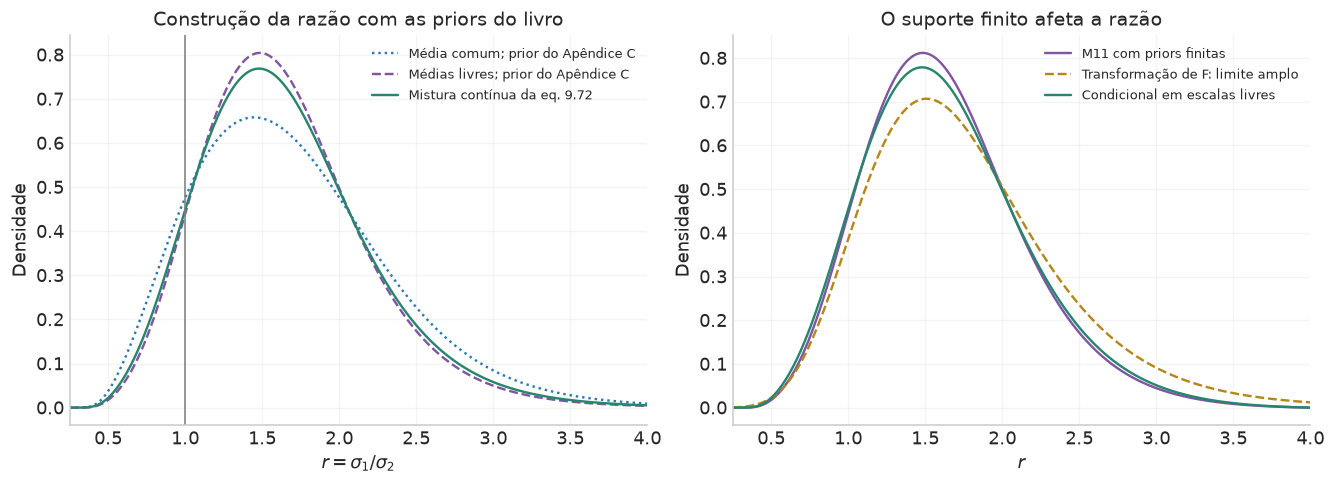

,Curva,Moda,Média,Mediana,IC central 95% inf.,IC central 95% sup.
0,"M01, priors originais",1.44504,1.65753,1.59449,0.70428,2.97134
1,"M11, priors originais",1.48338,1.63156,1.57870,0.77974,2.79834
2,Mistura contínua do livro,1.47882,1.65550,1.59054,0.75988,2.94879
3,Condicional em escalas livres,1.47882,1.63767,1.58189,0.75843,2.84631


In [21]:
def densidades_razao(lim,k_r=1801):
    lo,hi,a,b=lim;R=hi-lo;ell=np.log(b/a)
    Zloc=evidencias(*lim)
    # Grade logarítmica inclui exatamente r=1.
    r=np.geomspace(a/b,b/a,k_r)
    z,w=leggauss(110)
    smin=np.maximum(a,a/r)[:,None]
    smax=np.minimum(b,b/r)[:,None]
    em=np.log(smin);eM=np.log(smax)
    eta=em+(z[None,:]+1)*(eM-em)/2
    we=w[None,:]*(eM-em)/2
    s=np.exp(eta)
    h11=np.sum(we*B_grupo(n1,m1,q1,r[:,None]*s,lo,hi)*B_grupo(n2,m2,q2,s,lo,hi),axis=1)/(R*R*r*ell*ell)
    h01=np.sum(we*B_comum(r[:,None]*s,s,lo,hi),axis=1)/(R*r*ell*ell)
    g01=h01/Zloc[2];g11=h11/Zloc[3]
    verificar(f'Área g01 razão {lim}',np.isclose(integrate.trapezoid(g01,r),1,atol=5e-6))
    verificar(f'Área g11 razão {lim}',np.isclose(integrate.trapezoid(g11,r),1,atol=5e-6))
    return r,normalizar(r,g01),normalizar(r,g11)

def razao_prior_apendice(lim,k_r=1801):
    """Priors independentes em r e σ2 da seção C.4 do Gregory."""
    lo,hi,a,b=lim
    r=np.geomspace(a/b,b/a,k_r)
    eta,ww=quadratura_gl(np.log(a),np.log(b),110)
    s=np.exp(eta)[None,:]
    h01=(B_comum(r[:,None]*s,s,lo,hi)@ww)/r
    h11=((B_grupo(n1,m1,q1,r[:,None]*s,lo,hi)*B_grupo(n2,m2,q2,s,lo,hi))@ww)/r
    return r,normalizar(r,h01),normalizar(r,h11)

rg,gr01,gr11=densidades_razao(limites)
rB,grB01,grB11=razao_prior_apendice(limites)
g_r_livro=P_C*grB01+(1-P_C)*grB11
w01=P[2]/(P[2]+P[3])
g_r_cond=w01*gr01+(1-w01)*gr11
nu1,nu2=n1-1,n2-1
A_F=q1*nu2/(q2*nu1)
p_F=stats.f.pdf(rg**2/A_F,nu2,nu1)*2*rg/A_F
fig,ax=plt.subplots(1,2,figsize=(11.5,4.1),layout='constrained')
ax[0].plot(rB,grB01,':',color=AZUL,label='Média comum; prior do Apêndice C')
ax[0].plot(rB,grB11,'--',color=ROXO,label='Médias livres; prior do Apêndice C')
ax[0].plot(rB,g_r_livro,color=VERDE,label='Mistura contínua da eq. 9.72')
ax[0].axvline(1,color='gray',lw=1)
ax[0].set(xlabel=r'$r=\sigma_1/\sigma_2$',ylabel='Densidade',title='Construção da razão com as priors do livro',xlim=(.25,4))
ax[0].legend(fontsize=8.2)
ax[1].plot(rg,gr11,color=ROXO,label='M11 com priors finitas')
ax[1].plot(rg,p_F,'--',color=OURO,label='Transformação de F: limite amplo')
ax[1].plot(rg,g_r_cond,color=VERDE,label='Condicional em escalas livres')
ax[1].set(xlabel=r'$r$',ylabel='Densidade',title='O suporte finito afeta a razão',xlim=(.25,4))
ax[1].legend(fontsize=8.2)
figura(fig,'16_razao_de_escalas')
tabela(pd.DataFrame([{'Curva':nome,**resumo_grade(rg,p)} for nome,p in
                     [('M01, priors originais',gr01),('M11, priors originais',gr11),('Mistura contínua do livro',g_r_livro),('Condicional em escalas livres',g_r_cond)]]),
       'razao_resumos')

A cauda para razões grandes produz assimetria: a moda e a média aparecem em posições diferentes. Sob média comum, uma parte da diferença de nível entre os grupos precisa ser absorvida pelas escalas; isso também afeta a posterior da razão.

A equação (9.72) combina as curvas contínuas da etapa de estimação com pesos $P(C\mid D)$ e $P(\bar C\mid D)$, reproduzidos no primeiro painel. Ao preservar as priors originais, a densidade **condicionada em escalas livres** é

$$p(r\mid\bar S,D)=\frac{P_{01}g_{01}^{(r)}(r)+P_{11}g_{11}^{(r)}(r)}{P_{01}+P_{11}}.$$

Incluindo os quatro modelos, existe também uma massa pontual em $r=1$:

$$\boxed{p(dr\mid D)=P(S\mid D)\delta_1(dr)
+\left[P_{01}g_{01}^{(r)}(r)+P_{11}g_{11}^{(r)}(r)\right]dr.}$$

Aqui $P(S\mid D)\simeq0{,}387$. O intervalo central da curva contínua e a probabilidade de igualdade exata respondem a perguntas distintas. Na distribuição mista, uma densidade suave por si só representa apenas a componente contínua.

Nas tabelas deste notebook, os intervalos são **centrais de 95%**, definidos pelos quantis 2,5% e 97,5%. A assimetria torna relevantes tanto essa convenção quanto a prior escolhida ao comparar os limites com as anotações gráficas do livro. As integrais, as priors e a regra de resumo usados aqui estão explicitados. Para a mistura contínua da razão com as priors do Apêndice C, obtemos moda próxima de 1,48 e média próxima de 1,66; a Figura 9.7 anota 1,45 e 1,61. Essas anotações diferem ligeiramente dos resumos obtidos pelo recálculo. Conservamos os resultados das integrais declaradas para que a comparação com a fonte fique explícita. As probabilidades dos quatro modelos, por sua vez, concordam com as Tabelas 9.3–9.4 à precisão publicada.

In [22]:
pr_maior_cond=prob_acima_grade(rg,g_r_cond,1.)
tabela(pd.DataFrame({'Evento':['Escalas iguais: r = 1','σ1 > σ2: r > 1','σ1 < σ2: r < 1'],
                     'Probabilidade completa':[P_S,(1-P_S)*pr_maior_cond,(1-P_S)*(1-pr_maior_cond)]}),
       'razao_probabilidades')
verificar('Massa da distribuição completa de r',np.isclose(P_S+(1-P_S)*integrate.trapezoid(g_r_cond,rg),1))
# Normalização da transformação de F em toda a semirreta.
area_F=integrate.quad(lambda r:stats.f.pdf(r*r/A_F,nu2,nu1)*2*r/A_F,0,np.inf)[0]
verificar('Razão ampla derivada de F normalizada',np.isclose(area_F,1,atol=1e-8))

,Evento,Probabilidade completa
0,Escalas iguais: r = 1,0.38673
1,σ1 > σ2: r > 1,0.55088
2,σ1 < σ2: r < 1,0.06239


## 10. As priors afetam igualmente a estimação e a comparação?

As evidências variam com a faixa a priori porque integram a likelihood com uma prior normalizada. As densidades condicionais de parâmetros dentro de um mesmo modelo podem permanecer muito próximas quando suas regiões centrais ficam bem dentro das bordas.

Vamos reproduzir o último passo do capítulo: sobrepor, para as quatro escolhas de limites, as curvas contínuas de $\delta$ e $r$ com as priors da etapa de estimação do Apêndice C e os pesos usados no livro. Todas são recalculadas a partir das integrais, mantendo os respectivos limites finitos. A razão de escalas costuma sentir mais os limites de $\sigma$, pois o próprio suporte permitido para $r$ muda.

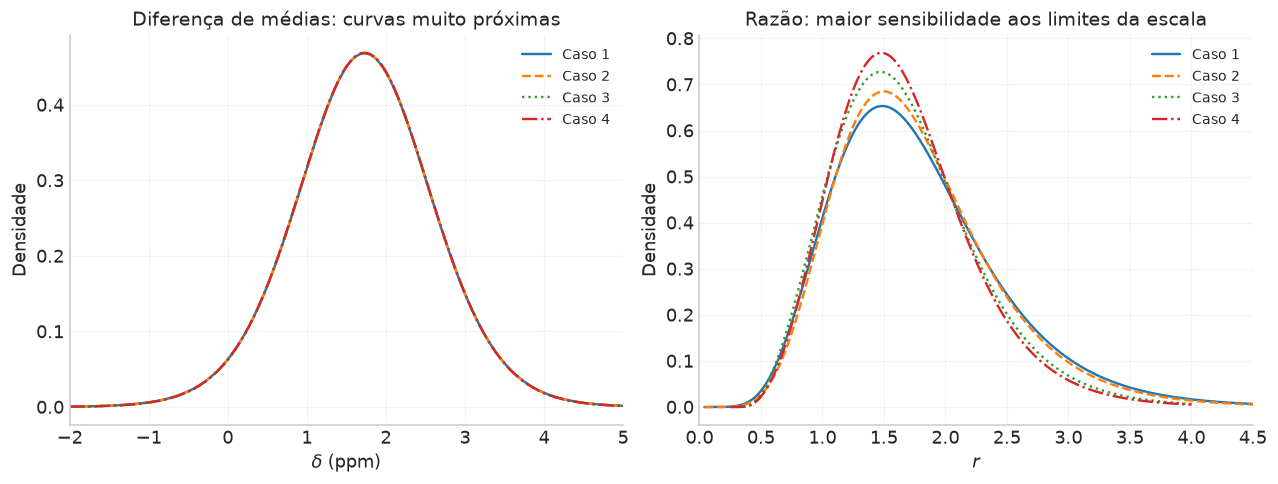

In [23]:
curvas_delta=[];curvas_r=[]
for caso,lim in enumerate(casos,1):
    if caso==4:
        dd,ga,gb=delta_B,gb10,gb11
        rr0,ra,rb=rB,grB01,grB11
    else:
        dd,ga,gb=delta_prior_apendice(lim,k_delta=1801)
        rr0,ra,rb=razao_prior_apendice(lim,k_r=1801)
    pp=P_casos[caso-1]
    pesoS=pp[0]+pp[1];pesoC=pp[0]+pp[2]
    curvas_delta.append((dd,pesoS*ga+(1-pesoS)*gb))
    curvas_r.append((rr0,pesoC*ra+(1-pesoC)*rb))
fig,ax=plt.subplots(1,2,figsize=(11,4.1),layout='constrained')
for j,((dd,pdlt),(rr0,pr)) in enumerate(zip(curvas_delta,curvas_r),1):
    ax[0].plot(dd,pdlt,label=f'Caso {j}',ls=['-', '--', ':', '-.'][j-1])
    ax[1].plot(rr0,pr,label=f'Caso {j}',ls=['-', '--', ':', '-.'][j-1])
ax[0].set(xlabel=r'$\delta$ (ppm)',ylabel='Densidade',title='Diferença de médias: curvas muito próximas',xlim=(-2,5))
ax[1].set(xlabel=r'$r$',ylabel='Densidade',title='Razão: maior sensibilidade aos limites da escala',xlim=(0,4.5))
for a in ax:a.legend()
figura(fig,'17_priors_e_estimacao')

## 11. Fechamento e ligação com o capítulo 10

| Informação e pergunta | Construção | Resultado principal |
|:--|:--|:--|
| Média, $\sigma_0$ conhecido e igual | Produto de normais; prior de localização ampla | $\mu\mid D\simeq\mathcal N(\bar d,\sigma_0^2/N)$ |
| Média, $\sigma_i$ conhecidos e distintos | Precisões $w_i=\sigma_i^{-2}$ | $\mu\mid D\simeq\mathcal N(\bar d_w,1/\sum_iw_i)$ |
| Média, escala comum desconhecida | Prior conjunta $1/\sigma$; integrar $\sigma$ | Student $t_{N-1}$ com escala $S/\sqrt N$, no limite amplo |
| A própria escala comum | Integrar a média; transformar $v=\sigma^2$ | $v\mid D\sim\operatorname{InvGamma}[(N-1)/2,q/2]$ no limite amplo |
| Dois grupos: quais relações são favorecidas? | Integrar cada likelihood com sua prior; aplicar Bayes entre quatro modelos | Probabilidades de médias/escalas comuns ou livres |
| Dois grupos: qual a magnitude das diferenças? | Transformar os parâmetros com jacobiano e suporte; integrar os auxiliares | Densidades de $\delta$ e $r$, condicionais ou mistas conforme a pergunta |

O exemplo da toxina explicita duas etapas complementares: atribuir probabilidade às relações entre parâmetros e estimar seus valores dentro de cada relação. As priors finitas entram em ambas; seus fatores de normalização são especialmente importantes nas evidências. Ao incluir modelos de igualdade exata, as distribuições completas de diferenças e razões contêm massas pontuais.

No capítulo 10, a previsão constante $m_i=\mu$ será substituída por uma combinação linear de funções conhecidas, com vários coeficientes. O procedimento segue o que acabamos de fazer: construir a likelihood a partir dos erros, combinar com a prior e marginalizar os parâmetros auxiliares. A álgebra das somas de quadrados passará a ser escrita em forma matricial.
